# Exploratory Data Analysis of the PLAID Dataset (Submetered Data)
### Appliance Identification from Voltage and Current Waveforms
**EC5203 Machine Learning · Group 6 – Team Plug Detectives**

   **Objective:** Understand the PLAID submetered recordings before feature extraction: what is in the data, what is wrong with it, and what that means for a classifier tested on **unseen homes**.

   **Dataset:** PLAID: 1,876 submetered recordings of 16 appliance types from 56 locations, with current and voltage sampled at 30 kHz (Medico et al., 2020, *Scientific Data* 7:49).

   **Output:** A cleaning plan (Section 13) and `clean_index.csv` (1,810 recordings, 11 types), the input to `02_feature_extraction.ipynb`.

## 1. Setup and Data Paths

In [51]:
import json
import re
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from tqdm.auto import tqdm          # progress bar
except ImportError:
    tqdm = lambda x: x

DATA  = Path.home() / "Documents" / "10084619"
WAVES = DATA / "submetered_new"
AGG   = DATA / "aggregated"
FS    = 30_000
SPC = FS // 60                     # 500 samples per mains cycle
STEADY_S = 20 * SPC / FS           # 0.333 s steady-state window
UNITS = {"w": 1, "watt": 1, "watts": 1, "kw": 1000, "": 1}
NAME_MAP = {"Iron solder": "Soldering Iron"}          # match the submetered label


def load_wave(rec_id):
    return pd.read_csv(WAVES / f"{rec_id}.csv", header=None, names=["current", "voltage"])

def rising_crossings(v, min_gap=int(0.8 * SPC)):
    """Upward zero crossings, ignoring noise wiggles closer than 0.8 cycle apart."""
    idx = np.flatnonzero((v[:-1] < 0) & (v[1:] >= 0))
    keep = []
    for k in idx:
        if not keep or k - keep[-1] >= min_gap:
            keep.append(k)
    return np.array(keep)

def last_cycle(w):
    v, i = w["voltage"].to_numpy(), w["current"].to_numpy()
    r = rising_crossings(v)
    start = r[r <= len(v) - SPC][-1]
    return i[start:start + SPC], v[start:start + SPC]

with open(DATA / "metadata_submetered.json") as f:
    meta_raw = json.load(f)

print("Records:", len(meta_raw))

rec_id = "1"                         # try "1", "1005", "1587"
print(json.dumps(meta_raw[rec_id], indent=2))

Records: 1876
{
  "appliance": {
    "brand": "",
    "current": "",
    "load": "NL",
    "manufacture_year": "",
    "model_number": "",
    "notes": "",
    "status": "off-on",
    "type": "Compact Fluorescent Lamp",
    "voltage": "",
    "wattage": ""
  },
  "header": {
    "collection_time": "July, 2013",
    "notes": "some instances are not well calibrated, meta data are not complete",
    "sampling_frequency": "30000Hz"
  },
  "instances": {
    "length": "2.00s"
  },
  "location": "house1"
}


## 2. Loading the Submetered Metadata

In [52]:
rows = []
for k, r in meta_raw.items():
    a = r["appliance"]
    rows.append({
        "id":              int(k),
        "type":            a["type"],
        "load":            a.get("load"),
        "status":          a.get("status"),
        "brand":           a.get("brand"),
        "wattage":         a.get("wattage"),
        "notes":           a.get("notes"),
        "location":        r["location"],
        "collection_time": r["header"]["collection_time"],
        "length_s":        float(r["instances"]["length"].rstrip("s")),
    })

meta = pd.DataFrame(rows).replace("", np.nan).sort_values("id").reset_index(drop=True)
print(meta.shape)
meta.head(10)

(1876, 10)


,id,type,load,status,brand,wattage,notes,location,collection_time,length_s
0,1,Compact Fluorescent Lamp,NL,off-on,NaN,NaN,NaN,house1,"July, 2013",2.0
1,2,Compact Fluorescent Lamp,NL,off-on,NaN,NaN,NaN,house1,"July, 2013",2.0
2,3,Compact Fluorescent Lamp,NL,off-on,NaN,NaN,NaN,house1,"July, 2013",2.0
3,4,Compact Fluorescent Lamp,NL,off-on,NaN,NaN,NaN,house1,"July, 2013",2.0
4,5,Compact Fluorescent Lamp,NL,off-on,NaN,NaN,NaN,house1,"July, 2013",2.0
5,6,Fridge,I,off-on,NaN,NaN,NaN,house1,"July, 2013",10.0
6,7,Hairdryer,R,off-on,NaN,NaN,NaN,house1,"July, 2013",2.0
7,8,Hairdryer,R,off-on,NaN,NaN,NaN,house1,"July, 2013",2.0
8,9,Air Conditioner,NL,off-on,NaN,NaN,NaN,house2,"July, 2013",5.0
9,10,Air Conditioner,NL,off-on,NaN,NaN,NaN,house2,"July, 2013",5.0


In [53]:
meta.info()

<class 'pandas.DataFrame'>
RangeIndex: 1876 entries, 0 to 1875
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1876 non-null   int64  
 1   type             1876 non-null   str    
 2   load             1876 non-null   str    
 3   status           1876 non-null   str    
 4   brand            823 non-null    str    
 5   wattage          452 non-null    str    
 6   notes            140 non-null    str    
 7   location         1876 non-null   str    
 8   collection_time  1876 non-null   str    
 9   length_s         1876 non-null   float64
dtypes: float64(1), int64(1), str(8)
memory usage: 146.7 KB


**Finding:** The metadata table has 1,876 rows and 11 columns.
All columns needed for modelling are **100% complete**:
`type` (target), `location` (group for the unseen-home split), `collection_time` / `batch_date`, `length_s`, `load`, `status`.

Missing values appear **only in descriptive nameplate fields**:

| Column | Missing | % missing |
|---|---|---|
| `brand` | 1,053 | 56.1% |
| `wattage` | 1,424 | 75.9% |
| `notes` | 1,736 | 92.5% |

Data types are correct after cleaning: `id` is integer, `length_s` is float, `batch_date` is datetime.
`wattage` is stored as **text with mixed units** (e.g. "60W", "200 mA"), so it is not usable as a number without parsing.

**Action:**
- **No imputation needed.** `brand`, `wattage` and `notes` are not model features: they would not be available for a new appliance, and they are too incomplete.
- Keep them for **EDA and sanity checks only** (e.g. compare measured power with nameplate wattage where it exists).
- **Features will come from the waveforms (CSV files)**, which have no missing values in the metadata link (`id` is complete).

## 3. Class Balance: Recordings per Appliance Type

type
Hairdryer                   246
Compact Fluorescent Lamp    230
Fan                         220
Laptop                      216
Air Conditioner             204
Microwave                   200
Incandescent Light Bulb     157
Fridge                      108
Heater                       85
Vacuum                       83
Washing Machine              75
Soldering Iron               20
Coffee maker                 10
Water kettle                 10
Hair Iron                    10
Blender                       2
Name: count, dtype: int64

Number of Types: 16


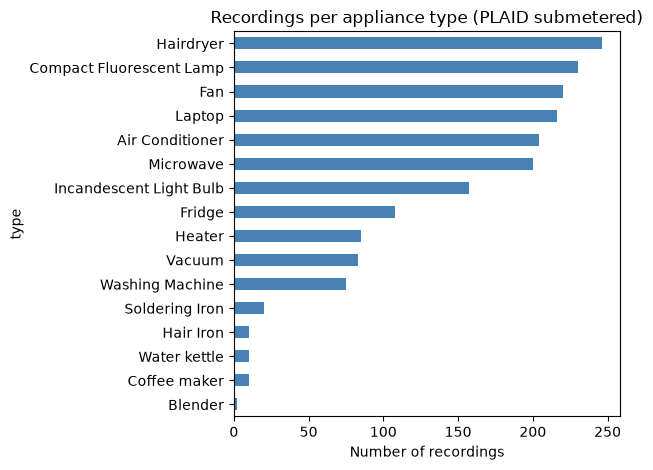

In [54]:
type_counts=meta["type"].value_counts()
print(type_counts)
print("\nNumber of Types:",type_counts.size)

plt.Figure(figsize=(10,5))
type_counts.sort_values().plot(kind="barh",color="steelblue")
plt.xlabel("Number of recordings")
plt.title("Recordings per appliance type (PLAID submetered)")
plt.tight_layout()
plt.show()


**Finding:** The submetered data has **16 appliance types** (the paper reports 17) and 1,876 recordings.
The classes are **strongly imbalanced**: Hairdryer has 246 recordings and Blender only 2, a ratio of **123 : 1**.

| Tier | Types | Recordings | Share |
|---|---|---|---|
| Large (150+) | Hairdryer, CFL, Fan, Laptop, AC, Microwave, Incandescent bulb | 1,473 | 78.5% |
| Medium (75–108) | Fridge, Heater, Vacuum, Washing Machine | 351 | 18.7% |
| Tiny (< 25) | Soldering Iron, Coffee maker, Water kettle, Hair Iron, Blender | 52 | 2.8% |

A model that always predicts *Hairdryer* would already score **13.1% accuracy**,
so accuracy alone would hide poor performance on small classes.


**Action:**
- **Main experiment:** use the **11 household types (1,824 recordings)**; imbalance drops to **3.3 : 1** (246 vs 75).
- Report **macro-F1** (treats every class equally) instead of accuracy alone, and compare against the 13.1% baseline.
- Use **stratified** splits so every class appears in each fold.
- The 5 lab-only types go into an optional, record-level experiment, clearly labelled as optimistic.

## 4. Locations: How Many Homes per Appliance Type

In [55]:
location_counts=meta["location"].value_counts()
print(location_counts)
print("\nNumber of Locations:",location_counts.size)

location
house2     172
house8     142
CMU lab    132
house6     121
house7     111
house4      87
house5      84
house3      80
house9      60
house1      38
house39     31
house44     31
house10     29
house20     29
house27     27
house28     27
house34     27
house40     26
house54     26
house11     25
house17     25
house23     25
house32     25
house38     25
house13     24
house21     24
house31     23
house33     23
house14     22
house49     22
house51     21
house12     20
house19     20
house24     20
house29     20
house25     18
house37     18
house22     17
house55     17
house30     16
house47     16
house52     16
house15     15
house50     14
house48     11
house41     10
house42     10
house43     10
house16      7
house18      7
house26      5
house35      5
house36      5
house45      5
house46      5
house53      5
Name: count, dtype: int64

Number of Locations: 56


In [56]:
summary = meta.groupby("type").agg(
    recordings=("id", "count"),
    houses=("location", "nunique"),
).sort_values("recordings", ascending=False)

summary["recs_per_house"] = (summary["recordings"] / summary["houses"]).round(1)
summary

,recordings,houses,recs_per_house
type,,,
Hairdryer,246,34,7.2
Compact Fluorescent Lamp,230,33,7.0
Fan,220,28,7.9
Laptop,216,37,5.8
Air Conditioner,204,18,11.3
Microwave,200,31,6.5
Incandescent Light Bulb,157,28,5.6
Fridge,108,25,4.3
Heater,85,10,8.5


**Finding:** The recordings come from **56 locations** (55 homes + CMU lab), but very unevenly:
from **172** recordings (house2) down to **5** (six homes); mean 33.5, median 22.5.
The top 5 locations hold **36.1%** of all recordings, and the top 10 hold **54.7%**.

Each appliance is usually recorded **several times in the same home** (4.3–11.3 recordings per home).
Air Conditioner is highest at **11.3 per home**, which matches its 4 operating modes (cool/fan × high/low).
Heater comes from only **10 homes**, the fewest of the 11 household types.
The 5 lab-only types each come from **1 location** (CMU lab).

**Why it matters:** recordings from the same home are **not independent**; they are often the same physical appliance.
If one home's recordings appear in both training and test sets, the model can memorise that unit,
and the score will be **over-optimistic** (data leakage).

**Action:**
- Split **by location** (`StratifiedGroupKFold`, `groups = location`) so test homes are never seen in training.
- Check that **every fold contains every class**; Heater (10 homes) is the class most at risk of missing from a fold.
- Report **mean ± std across folds**, because fold sizes vary (house2 alone is 9% of the data).
- After removing the 5 lab-only types, the remaining **80 CMU lab recordings** stay as one group.

## 5. Collection Batches and Possible Bias

Recordings per date:
 batch_date
Jul 2013    1026
Dec 2014     718
Aug 2017     132
dtype: int64 



batch_date,2013-07,2014-12,2017-08,Total
type,,,,
Total,1026,718,132,1876
Hairdryer,154,92,0,246
Compact Fluorescent Lamp,175,45,10,230
Fan,115,95,10,220
Laptop,171,35,10,216
Air Conditioner,53,141,10,204
Microwave,110,90,0,200
Incandescent Light Bulb,113,34,10,157
Fridge,36,52,20,108


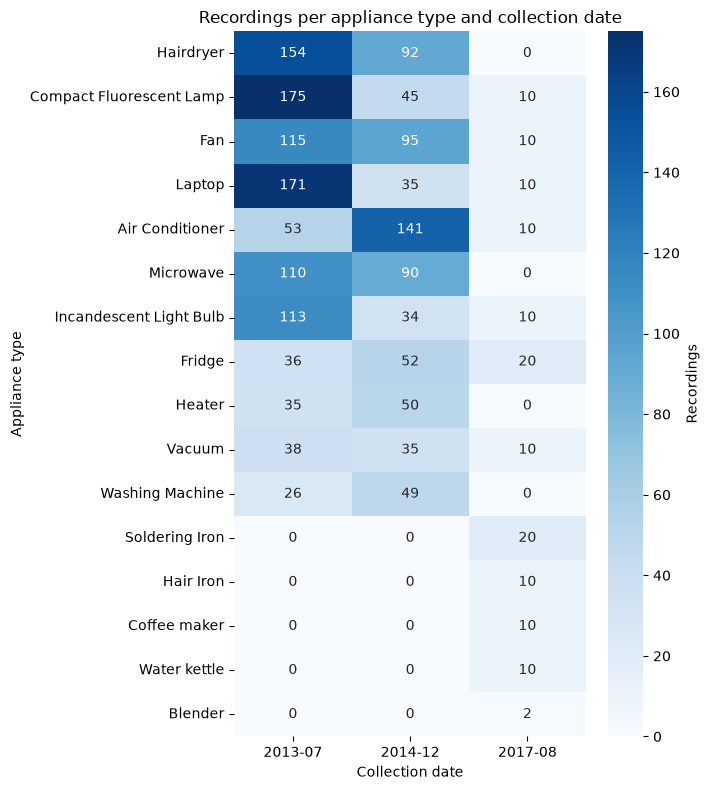

collection_time,"August, 2017","December, 2014","July, 2013"
location,,,
False,0,718,1026
True,132,0,0


collection_time,"August, 2017","December, 2014","July, 2013"
mode,,,
charging,0,15,0
high,0,81,0
highcool,0,49,0
highfan,0,34,0
highheat,0,6,0
highhot,0,20,0
highwarm,0,5,0
low,0,45,0
lowcool,0,44,0


In [57]:
# 1) Recordings per date, in time order
meta["batch_date"] = pd.to_datetime(meta["collection_time"], format="%B, %Y")
date_counts = meta.groupby("batch_date").size()
date_counts.index = date_counts.index.strftime("%b %Y")
print("Recordings per date:\n", date_counts, "\n")

# 2) Recordings per appliance type AND date
batch_table = pd.crosstab(meta["type"], meta["batch_date"].dt.strftime("%Y-%m"),
                          margins=True, margins_name="Total")
batch_table = batch_table.sort_values("Total", ascending=False)
display(batch_table)

# 3) Heatmap of the same table (without the Total row/column)
plt.figure(figsize=(7, 8))
sns.heatmap(batch_table.drop(index="Total", columns="Total"),
            annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Recordings"})
plt.title("Recordings per appliance type and collection date")
plt.xlabel("Collection date")
plt.ylabel("Appliance type")
plt.tight_layout()
plt.show()

display(pd.crosstab(meta["location"].eq("CMU lab"), meta["collection_time"]))
meta["mode"] = meta["status"].replace("off-on", "none")    # operating mode; "none" = plain switch-on
display(pd.crosstab(meta["mode"], meta["collection_time"]))


**Finding:** The data was collected in 3 batches, unevenly sized:
**Jul 2013 – 1,026 (54.7%)**, Dec 2014 – 718 (38.3%), Aug 2017 – 132 (7.0%).

The batch mix **differs by appliance type**:
- Mostly 2013: Laptop (79%), CFL (76%), Incandescent bulb (72%), Hairdryer (63%)
- Mostly 2014: Air Conditioner (69%), Washing Machine (65%), Heater (59%)
- Only 2017: all 5 lab-only types (Soldering Iron, Hair Iron, Coffee maker, Water kettle, Blender)

The **Aug 2017 batch matches the CMU lab** (132 recordings), and the **Dec 2014 batch appears to contain the
operating-mode recordings** (AC 141, Fan 95, Hairdryer 92, Microwave 90 match their mode counts exactly).

**Why it matters:** the 2013 batch is noted as "not well calibrated". Because some types come mostly from 2013
and others mostly from 2014, a model could learn **batch differences** (calibration, setup) instead of real
appliance signatures. This is **confounding**: two factors (type and batch) change together, so their effects get mixed up.

**Action:**
- Prefer **shape-based features** (power factor, THD, crest factor, harmonic ratios), which are less affected by calibration than absolute values (RMS current, power).
- **Check one type across batches:** e.g. boxplot a Fan's RMS current by batch; a large shift suggests a calibration effect.
- After training, report **accuracy per batch** to see whether 2013 recordings behave differently.
- Do **not** use `collection_time` as a feature: a new appliance has no batch.
- Lab-only types (100% 2017) are already excluded from the main experiment.

## 6. Load Type, Status and Operating Modes

In [58]:
# 1) Load type per appliance type
load_table = pd.crosstab(meta["type"], meta["load"].fillna("missing"))
display(load_table)

mixed = load_table[(load_table > 0).sum(axis=1) > 1]
print("Types with MORE than one load label:\n", mixed if len(mixed) else "None")

# 2) Status values
print("\nStatus counts:\n", meta["status"].value_counts(dropna=False))

status_table = pd.crosstab(meta["type"], meta["status"].fillna("missing"))
display(status_table)

# 3) Operating modes: read the notes for each type
for t, g in meta.groupby("type"):
    notes = g["notes"].dropna().str.strip().str.lower().value_counts()
    if len(notes):
        print(f"\n=== {t} ({len(g)} recordings) ===")
        print(notes.head(8))

load,I,NL,R
type,,,
Air Conditioner,0,204,0
Blender,2,0,0
Coffee maker,0,0,10
Compact Fluorescent Lamp,0,230,0
Fan,220,0,0
Fridge,108,0,0
Hair Iron,0,10,0
Hairdryer,0,0,246
Heater,0,0,85


Types with MORE than one load label:
 None

Status counts:
 status
off-on           1393
high               81
medium             79
highcool           49
low                45
lowcool            44
highfan            34
lowfan             34
highhot            20
lowhot             20
regular            20
charging           15
off-defroster      10
highheat            6
lowheat             6
noheat              5
mediumhot           5
highwarm            5
lowwarm             5
Name: count, dtype: int64


status,charging,high,highcool,highfan,highheat,highhot,highwarm,low,lowcool,lowfan,lowheat,lowhot,lowwarm,medium,mediumhot,noheat,off-defroster,off-on,regular
type,,,,,,,,,,,,,,,,,,,
Air Conditioner,0,0,39,34,0,0,0,0,34,34,0,0,0,0,0,0,0,63,0
Blender,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0
Coffee maker,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10,0
Compact Fluorescent Lamp,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,230,0
Fan,0,35,0,0,0,0,0,30,0,0,0,0,0,30,0,0,0,125,0
Fridge,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10,98,0
Hair Iron,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,10,0
Hairdryer,0,0,10,0,6,20,5,0,10,0,6,20,5,0,5,5,0,154,0
Heater,0,20,0,0,0,0,0,15,0,0,0,0,0,5,0,0,0,45,0



=== Air Conditioner (204 recordings) ===
notes
for high cool mode: long transient(~2s), than fun, than compressor    23
4.0cbf                                                                19
Name: count, dtype: int64

=== Compact Fluorescent Lamp (230 recordings) ===
notes
1600lumins     10
800 lumens      5
840 lumens      5
1600 lumens     5
150 lumens      5
605 lumens      5
Name: count, dtype: int64

=== Fan (220 recordings) ===
notes
3 modes (didnt use ionizer)    15
Name: count, dtype: int64

=== Fridge (108 recordings) ===
notes
1600lumins    5
Name: count, dtype: int64

=== Incandescent Light Bulb (157 recordings) ===
notes
450 lumens    10
465 lumens     5
700 lumens     5
4.0cbf         4
Name: count, dtype: int64

=== Vacuum (83 recordings) ===
notes
(has carpet mode and floor mode, only used one)    5
Name: count, dtype: int64

=== Washing Machine (75 recordings) ===
notes
the non linear part is the rinse cycle. the sinusoidal part above 4 wtts of current is normal spin

**Finding:** 7 of 16 types were recorded in several operating modes (483 recordings, 26%).
AC fan-mode (68) and hairdryer cool/no-heat (25) are motor-only and may look like a Fan;
microwave "medium" may cycle on/off; fridge defrost (10) behaves like a heater.

**Action:** Keep all modes (real behaviour). Do not use status/mode as a feature.
Check microwave-medium steady-state windows. Use mode for per-mode error analysis after training.

**Finding:** Every appliance type has exactly one load code (51% NL, 27% R, 22% I).
Hairdryer (R) includes cool/no-heat recordings that behave like motors, and AC is labelled NL (likely inverter-driven).

**Action:** Do not use `load` as a feature (leakage). Use it to sanity-check PF, THD and inrush features per family.

## 7. Recording Length and Notes

count    1876.00
mean        3.48
std         2.12
min         0.70
25%         2.00
50%         3.00
75%         4.47
max        20.92
Name: length_s, dtype: float64


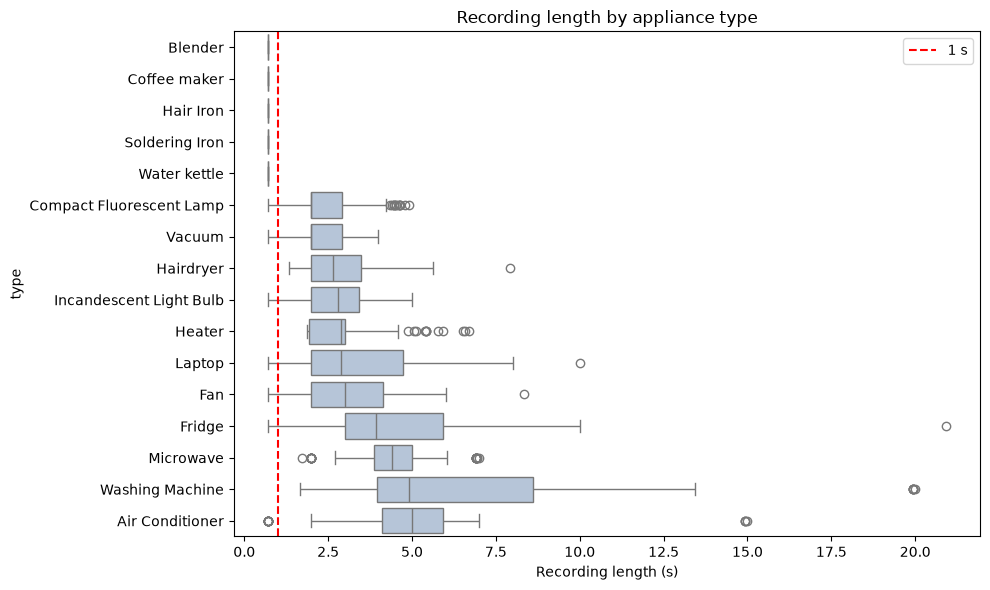

,count,mean,std,min,25%,50%,75%,max
collection_time,,,,,,,,
"August, 2017",132.0,0.70,0.00,0.70,0.70,0.70,0.70,0.70
"December, 2014",718.0,4.37,2.57,1.73,2.92,3.92,5.92,20.92
"July, 2013",1026.0,3.22,1.40,1.00,2.00,3.00,4.27,13.43


,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
False,483.0,4.14,1.93,0.7,2.92,3.92,5.92,15.00
True,1393.0,3.25,2.13,0.7,2.00,2.92,4.23,20.92


Recordings under 2 s: 255


too_close,False,True
type,,
Air Conditioner,0,10
Blender,0,2
Coffee maker,0,10
Compact Fluorescent Lamp,27,10
Fan,14,10
Fridge,1,20
Hair Iron,0,10
Hairdryer,35,0
Heater,24,0


In [59]:
# 1) Overall length
print(meta["length_s"].describe().round(2))

# 2) Length by appliance type
order = meta.groupby("type")["length_s"].median().sort_values().index
plt.figure(figsize=(10, 6))
sns.boxplot(data=meta, y="type", x="length_s", order=order, color="lightsteelblue")
plt.axvline(1.0, color="red", linestyle="--", label="1 s")
plt.xlabel("Recording length (s)")
plt.title("Recording length by appliance type")
plt.legend()
plt.tight_layout()
plt.show()

# 3) Length by batch and by switch-on status
display(meta.groupby("collection_time")["length_s"].describe().round(2))
display(meta.groupby(meta["status"].eq("off-on"))["length_s"].describe().round(2))

# 4) Short recordings: where does the switch-on happen?
def onset_s(rec_id):
    i = pd.read_csv(WAVES / f"{rec_id}.csv", header=None, usecols=[0])[0].to_numpy()
    n = len(i) // SPC
    cyc_rms = np.sqrt((i[:n * SPC].reshape(n, SPC) ** 2).mean(axis=1))
    on = np.flatnonzero(cyc_rms > 0.5 * cyc_rms[-20:].mean())
    return on[0] / 60 if len(on) else np.nan

short = meta[meta["length_s"] < 2.0].copy()
short["onset_s"] = short["id"].apply(onset_s)
short["steady_start_s"] = short["length_s"] - STEADY_S
short["too_close"] = short["onset_s"] + 0.2 > short["steady_start_s"]

print("Recordings under 2 s:", len(short))
display(pd.crosstab(short["type"], short["too_close"]))

In [60]:
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 80)

# 5) Most common notes
print(meta["notes"].dropna().str.strip().str.lower().value_counts().head(20))

# 6) Every note next to its type, to read through (about 140 rows)
meta.loc[meta["notes"].notna(), ["id", "type", "status", "collection_time", "notes"]].sort_values("type")

notes
4.0cbf                                                                                                      28
for high cool mode: long transient(~2s), than fun, than compressor                                          23
3 modes (didnt use ionizer)                                                                                 15
1600lumins                                                                                                  15
450 lumens                                                                                                  10
the non linear part is the rinse cycle. the sinusoidal part above 4 wtts of current is normal spin cycle     9
800 lumens                                                                                                   5
465 lumens                                                                                                   5
840 lumens                                                                                                

,id,type,status,collection_time,notes
1431,1432,Air Conditioner,lowfan,"December, 2014",4.0cbf
1595,1596,Air Conditioner,highfan,"December, 2014","for high cool mode: long transient(~2s), than fun, than compressor"
1594,1595,Air Conditioner,highcool,"December, 2014","for high cool mode: long transient(~2s), than fun, than compressor"
1415,1416,Air Conditioner,highcool,"December, 2014",4.0cbf
1429,1430,Air Conditioner,lowfan,"December, 2014",4.0cbf
1428,1429,Air Conditioner,lowfan,"December, 2014",4.0cbf
1427,1428,Air Conditioner,lowcool,"December, 2014",4.0cbf
1426,1427,Air Conditioner,lowcool,"December, 2014",4.0cbf
1425,1426,Air Conditioner,lowcool,"December, 2014",4.0cbf
1424,1425,Air Conditioner,lowcool,"December, 2014",4.0cbf



**Finding (length):** Recordings last 0.70–20.92 s (median 3.00 s). Length depends on the batch:
all **132 Aug 2017 (CMU lab) recordings are exactly 0.70 s**, Dec 2014 recordings are longest (median 3.92 s),
and mode recordings are longer than off-on recordings (median 3.92 s vs 2.92 s).
Because length reflects the recording setup, not the appliance, it is **not used as a feature**.

**Finding (steady-state window):** Of 255 recordings under 2 s, **123 switch on too close to the end**
for a clean 0.33 s steady-state window; these match the 0.7 s lab recordings.
In the main 11-type experiment this affects **71 recordings (3.9%)**, mostly Fridge (20), AC, CFL, Fan and Vacuum (10 each).

**Finding (notes):** Notes exist only for the Dec 2014 batch (140 recordings). Useful notes confirm
AC cooling has a ~2 s start-up transient, fans have 3 speeds, and the washing machine has two phases
(non-linear rinse vs sinusoidal spin). Notes were **copy-pasted forward**: "4.0cbf" (a washing-machine drum size)
appears on 19 AC and 4 bulb records, and "1600lumins" (a lamp rating) on 5 fridge records.

**Action:**
- Do not use `length_s` or `notes` as features.
- Flag the 71 short recordings; train with and without them and compare (sensitivity check).
- Find each recording's switch-on and take the steady-state window from after it settles, instead of blindly using the last 20 cycles.
- Treat notes as unreliable per record; spot-check labels near copy-paste blocks (ids 1410–1437, 1715–1724).

## 8. Data Quality: Missing Values and Errors in the Metadata

In [61]:
missing = pd.DataFrame({
    "missing": meta.isna().sum(),
    "pct":     (meta.isna().mean() * 100).round(1),
})
display(missing[missing["missing"] > 0])

# Is the missingness systematic? Share of FILLED values per batch
display(meta.groupby("collection_time")[["brand", "wattage", "notes"]]
            .apply(lambda g: g.notna().mean().round(2)))

,missing,pct
brand,1053,56.1
wattage,1424,75.9
notes,1736,92.5


,brand,wattage,notes
collection_time,,,
"August, 2017",0.98,0.53,0.00
"December, 2014",0.97,0.53,0.19
"July, 2013",0.00,0.00,0.00


In [62]:
rows = []
for k, r in meta_raw.items():
    a = r["appliance"]
    rows.append({
        "id":               int(k),
        "type":             a["type"],
        "brand":            a.get("brand"),
        "model_number":     a.get("model_number"),
        "np_current":       a.get("current"),
        "np_voltage":       a.get("voltage"),
        "np_wattage":       a.get("wattage"),
        "manufacture_year": a.get("manufacture_year"),
    })
#precetage of missing values in the metadata
plate = pd.DataFrame(rows).replace("", np.nan).sort_values("id").reset_index(drop=True)
display(plate.isna().mean().mul(100).round(1).rename("% missing"))

id                   0.0
type                 0.0
brand               56.1
model_number        69.0
np_current          76.1
np_voltage          65.1
np_wattage          75.9
manufacture_year    98.8
Name: % missing, dtype: float64

In [63]:
def formats(col):
    """Replace every digit with 9 to show the FORMAT of each value."""
    return plate[col].dropna().astype(str).str.strip().str.replace(r"\d", "9", regex=True).value_counts()
#easy to see pattern to undestand different formats of the values in the metadata
for col in ["np_wattage", "np_current", "np_voltage", "manufacture_year"]:
    print(f"\n=== {col} ===")
    print(formats(col).head(12))


=== np_wattage ===
np_wattage
9999     200
99        75
999       60
99W       30
999W      30
999.9     23
99.9W     19
9999W     10
9          5
Name: count, dtype: int64

=== np_current ===
np_current
9.9       138
99         85
9.99       75
9          42
9 A        30
99.9       29
9.9 A      20
999 mA     10
99A        10
9.99 A     10
Name: count, dtype: int64

=== np_voltage ===
np_voltage
999           534
999V          100
999-999        10
999 - 999V     10
Name: count, dtype: int64

=== manufacture_year ===
manufacture_year
9/9/9999    23
Name: count, dtype: int64


In [64]:
def to_watts(text):
    if pd.isna(text):
        return np.nan
    s = str(text).lower().replace(" ", "")
    m = re.fullmatch(r"([\d.]+)([a-z]*)", s)
    if not m or m.group(2) not in UNITS:
        return np.nan                          # unusual format -> needs a manual look
    return float(m.group(1)) * UNITS[m.group(2)]

plate["watts"] = plate["np_wattage"].apply(to_watts)
failed = plate[plate["np_wattage"].notna() & plate["watts"].isna()]
print("Wattage values that could not be parsed:", len(failed))
display(failed[["id", "type", "np_wattage"]].drop_duplicates("np_wattage"))

display(plate.groupby("type")["watts"].describe()[["count", "min", "50%", "max"]].round(0))

Wattage values that could not be parsed: 0


,id,type,np_wattage


,count,min,50%,max
type,,,,
Air Conditioner,132.0,61.0,740.0,1560.0
Blender,0.0,NaN,NaN,NaN
Coffee maker,10.0,975.0,975.0,975.0
Compact Fluorescent Lamp,55.0,7.0,13.0,26.0
Fan,5.0,48.0,48.0,48.0
Fridge,5.0,23.0,23.0,23.0
Hair Iron,0.0,NaN,NaN,NaN
Hairdryer,55.0,1875.0,1875.0,1875.0
Heater,50.0,800.0,1500.0,1500.0


In [65]:
# Manufacture year: keep any 4-digit year, flag impossible ones
plate["year"] = pd.to_numeric(plate["manufacture_year"].astype(str).str.extract(r"(\d{4})")[0],
                              errors="coerce")
bad_year = plate[(plate["year"] < 1980) | (plate["year"] > 2017)]
print("Impossible manufacture years:", len(bad_year))
display(bad_year[["id", "type", "manufacture_year"]])

# Label consistency: stray spaces or capitalisation in type / location
print("\nType values:", sorted(meta["type"].unique()))
print("Types with extra spaces:", (meta["type"] != meta["type"].str.strip()).sum())
print("Location name patterns:", meta["location"].str.replace(r"\d", "9", regex=True).value_counts().to_dict())

# Brand spellings that merge after cleaning
b = plate["brand"].dropna()
print("\nBrands raw:", b.nunique(), "| after lower/strip:", b.str.lower().str.strip().nunique())

Impossible manufacture years: 23


,id,type,manufacture_year
1586,1587,Air Conditioner,7/3/1905
1587,1588,Air Conditioner,7/3/1905
1588,1589,Air Conditioner,7/3/1905
1589,1590,Air Conditioner,7/3/1905
1590,1591,Air Conditioner,7/3/1905
1591,1592,Air Conditioner,7/3/1905
1592,1593,Air Conditioner,7/3/1905
1593,1594,Air Conditioner,7/3/1905
1594,1595,Air Conditioner,7/3/1905
1595,1596,Air Conditioner,7/3/1905



Type values: ['Air Conditioner', 'Blender', 'Coffee maker', 'Compact Fluorescent Lamp', 'Fan', 'Fridge', 'Hair Iron', 'Hairdryer', 'Heater', 'Incandescent Light Bulb', 'Laptop', 'Microwave', 'Soldering Iron', 'Vacuum', 'Washing Machine', 'Water kettle']
Types with extra spaces: 0
Location name patterns: {'house9': 895, 'house99': 849, 'CMU lab': 132}

Brands raw: 54 | after lower/strip: 54



**Finding (missing):** All modelling columns (`type`, `location`, `collection_time`, `length_s`) are complete.
Nameplate fields are mostly missing: brand 56.1%, model number 69.0%, voltage 65.1%, wattage 75.9%,
current 76.1%, manufacture year 98.8%. Missingness is **systematic by batch**: the **Jul 2013 batch has
no brand, wattage or notes at all**, while 2014 and 2017 have brand for ~97% of recordings and wattage for ~53%.

**Finding (errors):**
- **Mixed formats:** wattage appears as "1875" (no unit, 363 values) and "60W" (89 values).
- **Mixed units:** current mixes A and **mA** (10 values) — "200 mA" would be read as 200 A if not converted.
- **Ranges:** 20 voltage values are ranges (e.g. "100-240V", universal chargers).
- **Impossible date:** all 23 manufacture years are "7/3/1905" (AC ids 1587–1609). This is spreadsheet
  day number **2011** shown as a date, so the true value was most likely the year 2011.
- **Copy-paste carry-over:** fridge ids 1720–1724 have wattage 23 W and the note "1600lumins",
  both copied from the preceding CFL records (a 1,600-lumen CFL is ~23 W). AC minimum wattage (61 W) is also implausible.
- **Clean:** `type` (16 values), `location` ("houseN" / "CMU lab") and brand spellings (54) are consistent.

**Action:**
- No imputation: nameplate fields are **not used as features** (incomplete, unreliable, unavailable for new appliances).
- Parse units (W, A, mA) before any sanity check, and use nameplate wattage only where it is plausible for its type.
- Ids 1720–1724 confirmed as fridges in defrost mode (Section 9).
- Log all error types in the cleaning plan (Section 13).

## 9. Checking Metadata Against the CSV Files

In [66]:
file_ids = sorted(int(p.stem) for p in WAVES.glob("*.csv") if p.stem.isdigit())
other    = [p.name for p in WAVES.glob("*") if not p.stem.isdigit()]
meta_ids = set(meta["id"])

print("CSV files:", len(file_ids), "| metadata ids:", len(meta_ids))
print("In metadata but no file:", sorted(meta_ids - set(file_ids))[:20])
print("File but no metadata:",   sorted(set(file_ids) - meta_ids)[:20])
print("Other files in folder:",  other[:10])

CSV files: 1876 | metadata ids: 1876
In metadata but no file: []
File but no metadata: []
Other files in folder: ['.DS_Store']


In [67]:
def check_file(rec_id):
    path = WAVES / f"{rec_id}.csv"
    w = pd.read_csv(path, header=None)
    i, v = w[0].to_numpy(), w[1].to_numpy()

    rising = np.flatnonzero((v[:-1] < 0) & (v[1:] >= 0)) #Calculate Up and down point
    freq = (len(rising) - 1) * FS / (rising[-1] - rising[0]) if len(rising) > 2 else np.nan #calculate Frequncy

    return {
        "id":        rec_id,
        "n_cols":    w.shape[1],
        "n_rows":    len(w),
        "n_nan":     int(w.isna().sum().sum()),
        "v_rms":     np.sqrt(np.mean(v ** 2)),
        "v_peak":    np.abs(v).max(),
        "freq_hz":   freq,
        "i_rms_end": np.sqrt(np.mean(i[-20 * SPC:] ** 2)),
        "i_peak":    np.abs(i).max(),
        "md5":       hashlib.md5(path.read_bytes()).hexdigest(),
    }

checks = pd.DataFrame([check_file(r) for r in tqdm(meta["id"])])
checks.to_csv(DATA / "file_checks.csv", index=False)  # saved: next time just read this file
chk = meta.merge(checks, on="id")

count    1876.000000
mean       -0.000665
std         0.001955
min        -0.003000
25%        -0.003000
50%         0.000000
75%         0.000000
max         0.003000
Name: len_diff, dtype: float64
Length mismatch > 0.05 s: 0

Columns per file:
 n_cols
2    1876
Name: count, dtype: int64
Files with NaN: 0


v_rms                  v_peak                  freq_hz  \
                    min  median     max     min  median      max     min   
collection_time                                                            
August, 2017     116.19  121.69  122.70  173.03  175.07   219.05   59.96   
December, 2014   110.75  116.32  121.52  153.12  166.81   177.41   59.78   
July, 2013       120.00  120.00  120.00  166.42  175.87  1387.70   59.84   

                                
                median     max  
collection_time                 
August, 2017     59.99   61.45  
December, 2014   60.00  144.82  
July, 2013       60.01  121.68

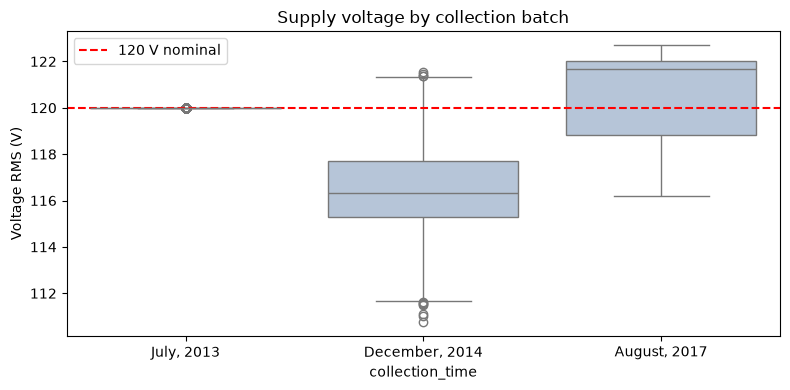

Steady current < 0.05 A: 43


,id,type,status,collection_time,i_rms_end
404,405,Compact Fluorescent Lamp,off-on,"July, 2013",0.041922
405,406,Compact Fluorescent Lamp,off-on,"July, 2013",0.043256
406,407,Compact Fluorescent Lamp,off-on,"July, 2013",0.044490
407,408,Compact Fluorescent Lamp,off-on,"July, 2013",0.043489
408,409,Compact Fluorescent Lamp,off-on,"July, 2013",0.042932
453,454,Laptop,off-on,"July, 2013",0.025308
807,808,Compact Fluorescent Lamp,off-on,"July, 2013",0.032228
808,809,Compact Fluorescent Lamp,off-on,"July, 2013",0.031365
809,810,Compact Fluorescent Lamp,off-on,"July, 2013",0.031216
810,811,Compact Fluorescent Lamp,off-on,"July, 2013",0.030498


Exact duplicate files: 10


,id,type,location,collection_time
223,224,Laptop,house11,"July, 2013"
368,369,Laptop,house19,"July, 2013"
224,225,Laptop,house11,"July, 2013"
369,370,Laptop,house19,"July, 2013"
222,223,Laptop,house11,"July, 2013"
367,368,Laptop,house19,"July, 2013"
225,226,Laptop,house11,"July, 2013"
370,371,Laptop,house19,"July, 2013"
221,222,Laptop,house11,"July, 2013"
366,367,Laptop,house19,"July, 2013"


In [68]:
# a) Length: metadata vs rows
chk["len_diff"] = (chk["n_rows"] / FS - chk["length_s"]).round(3)
print(chk["len_diff"].describe())
print("Length mismatch > 0.05 s:", (chk["len_diff"].abs() > 0.05).sum())

# b) Format
print("\nColumns per file:\n", chk["n_cols"].value_counts())
print("Files with NaN:", (chk["n_nan"] > 0).sum())

# c) Voltage and frequency by batch (calibration test)
display(chk.groupby("collection_time")[["v_rms", "v_peak", "freq_hz"]]
           .agg(["min", "median", "max"]).round(2))

plt.figure(figsize=(8, 4))
sns.boxplot(data=chk, x="collection_time", y="v_rms", color="lightsteelblue")
plt.axhline(120, color="red", linestyle="--", label="120 V nominal")
plt.ylabel("Voltage RMS (V)"); plt.title("Supply voltage by collection batch")
plt.legend(); plt.tight_layout(); plt.show()

# d) Appliance off in the steady window
dead = chk[chk["i_rms_end"] < 0.05]
print("Steady current < 0.05 A:", len(dead))
display(dead[["id", "type", "status", "collection_time", "i_rms_end"]])

# e) Exact duplicates
dups = chk[chk.duplicated("md5", keep=False)].sort_values("md5")
print("Exact duplicate files:", len(dups))
display(dups[["id", "type", "location", "collection_time"]])

In [69]:
 # Typical steady current for each type
typ = chk.groupby("type")["i_rms_end"].median().rename("type_median")
chk = chk.drop(columns="type_median", errors="ignore").merge(typ, on="type")
chk["ratio"] = chk["i_rms_end"] / chk["type_median"]

# The copy-paste block: CFL (1715-1719) vs "Fridge" (1720-1724)
display(chk[chk["id"].between(1714, 1725)][["id", "type", "i_rms_end", "type_median", "ratio"]].round(3))

# Recordings far from their type's typical current (> 5x or < 1/5)
odd = chk[(chk["ratio"] > 5) | (chk["ratio"] < 0.2)]
print("Far from type median:", len(odd))
display(pd.crosstab(odd["type"], odd["status"]))

,id,type,i_rms_end,type_median,ratio
1713,1714,Washing Machine,3.330,3.526,0.944
1714,1715,Compact Fluorescent Lamp,0.147,0.143,1.034
1715,1716,Compact Fluorescent Lamp,0.143,0.143,1.001
1716,1717,Compact Fluorescent Lamp,0.143,0.143,1.003
1717,1718,Compact Fluorescent Lamp,0.144,0.143,1.013
1718,1719,Compact Fluorescent Lamp,0.146,0.143,1.024
1719,1720,Fridge,6.606,1.849,3.573
1720,1721,Fridge,6.492,1.849,3.511
1721,1722,Fridge,6.422,1.849,3.473
1722,1723,Fridge,6.388,1.849,3.455


Far from type median: 89


status,charging,medium,noheat,off-on
type,,,,
Air Conditioner,0,0,0,16
Blender,0,0,0,1
Fridge,0,0,0,17
Hairdryer,0,0,5,0
Laptop,3,0,0,16
Microwave,0,3,0,0
Vacuum,0,0,0,10
Washing Machine,0,0,0,18


In [70]:
# The copy-paste block: CFL (1715-1719) vs "Fridge" (1720-1724)
display(chk[chk["id"].between(1714, 1725)][["id", "type", "i_rms_end", "type_median", "ratio"]].round(3))

,id,type,i_rms_end,type_median,ratio
1713,1714,Washing Machine,3.330,3.526,0.944
1714,1715,Compact Fluorescent Lamp,0.147,0.143,1.034
1715,1716,Compact Fluorescent Lamp,0.143,0.143,1.001
1716,1717,Compact Fluorescent Lamp,0.143,0.143,1.003
1717,1718,Compact Fluorescent Lamp,0.144,0.143,1.013
1718,1719,Compact Fluorescent Lamp,0.146,0.143,1.024
1719,1720,Fridge,6.606,1.849,3.573
1720,1721,Fridge,6.492,1.849,3.511
1721,1722,Fridge,6.422,1.849,3.473
1722,1723,Fridge,6.388,1.849,3.455


In [71]:
# Recordings far from their type's typical current (> 5x or < 1/5)
odd = chk[(chk["ratio"] > 5) | (chk["ratio"] < 0.2)]
print("Far from type median:", len(odd))
display(pd.crosstab(odd["type"], odd["status"]))

Far from type median: 89


status,charging,medium,noheat,off-on
type,,,,
Air Conditioner,0,0,0,16
Blender,0,0,0,1
Fridge,0,0,0,17
Hairdryer,0,0,5,0
Laptop,3,0,0,16
Microwave,0,3,0,0
Vacuum,0,0,0,10
Washing Machine,0,0,0,18


,id,type,collection_time,v_rms,v_peak,freq_hz
6,7,Hairdryer,"July, 2013",120.000032,178.630000,61.997009
7,8,Hairdryer,"July, 2013",120.000224,176.070000,62.506301
32,33,Air Conditioner,"July, 2013",119.999975,228.680000,59.987561
51,52,Incandescent Light Bulb,"July, 2013",119.999986,317.540000,59.979839
52,53,Incandescent Light Bulb,"July, 2013",120.000106,202.350000,59.979839
...,...,...,...,...,...,...
1025,1026,Washing Machine,"July, 2013",120.000193,174.180000,67.403352
1715,1716,Compact Fluorescent Lamp,"December, 2014",115.641160,165.080000,144.816054
1849,1850,Laptop,"August, 2017",122.033703,219.046805,59.982444
1852,1853,Laptop,"August, 2017",122.130210,175.069099,61.436443


short_window,False,True
type,,
Air Conditioner,16,0
Blender,0,1
Fridge,17,0
Hairdryer,5,0
Laptop,17,2
Microwave,3,0
Vacuum,10,0
Washing Machine,18,0


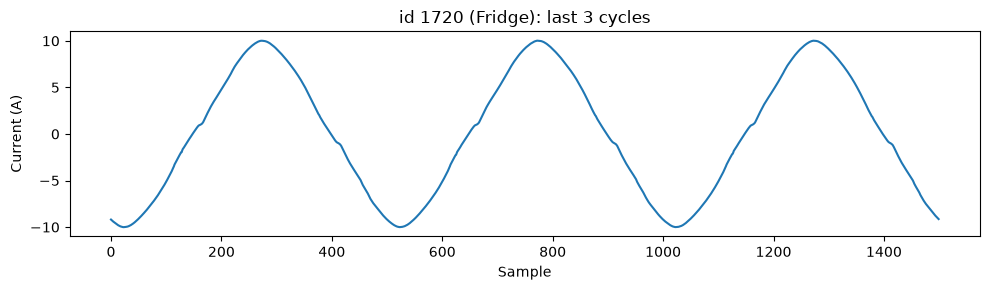

In [72]:
# 1) Voltage glitch files
glitch = chk[(chk["v_peak"] > 200) | (~chk["freq_hz"].between(59.5, 60.5))]
display(glitch[["id", "type", "collection_time", "v_rms", "v_peak", "freq_hz"]])

# 2) Are the "odd" recordings the short-window ones from Section 7?
too_close_ids = set(short.loc[short["too_close"], "id"])
odd = odd.assign(short_window=odd["id"].isin(too_close_ids))
display(pd.crosstab(odd["type"], odd["short_window"]))

# 3) Fridge 1720: heater (clean sine) or compressor (distorted)?
i = pd.read_csv(WAVES / "1720.csv", header=None, usecols=[0])[0].to_numpy()
plt.figure(figsize=(10, 3)); plt.plot(i[-3 * SPC:])
plt.title("id 1720 (Fridge): last 3 cycles"); plt.xlabel("Sample"); plt.ylabel("Current (A)")
plt.tight_layout(); plt.show()

In [73]:
def robust_freq(rec_id):
    v = pd.read_csv(WAVES / f"{rec_id}.csv", header=None, usecols=[1])[1].to_numpy()
    r = rising_crossings(v)
    return (len(r) - 1) * FS / (r[-1] - r[0])

# Recompute frequency for the flagged files only
glitch = glitch.assign(freq_robust=glitch["id"].apply(robust_freq))
print(glitch["freq_robust"].describe().round(3))

# Real voltage spikes (independent of the frequency issue)
print("\nFiles with voltage peak > 200 V:", (chk["v_peak"] > 200).sum())
display(chk[chk["v_peak"] > 200].groupby("collection_time").size())

count    452.000
mean      59.980
std        0.048
min       59.614
25%       59.978
50%       59.989
75%       60.001
max       60.201
Name: freq_robust, dtype: float64

Files with voltage peak > 200 V: 35


collection_time
August, 2017     1
July, 2013      34
dtype: int64

In [74]:
odd = odd.assign(direction=np.where(odd["ratio"] > 1, "high", "low"))
display(pd.crosstab(odd["type"], odd["direction"]))
display(odd.groupby("type")["location"].nunique().rename("houses"))

direction,high,low
type,,
Air Conditioner,16,0
Blender,0,1
Fridge,2,15
Hairdryer,0,5
Laptop,0,19
Microwave,0,3
Vacuum,0,10
Washing Machine,0,18


type
Air Conditioner    9
Blender            1
Fridge             9
Hairdryer          1
Laptop             4
Microwave          2
Vacuum             2
Washing Machine    5
Name: houses, dtype: int64


**Finding (structure):** All 1,876 CSV files match their metadata ids one-to-one. Row counts match
`length_s` within ±0.003 s (rounding). Every file has 2 columns and no missing values.

**Finding (voltage and frequency):** Mains frequency is ~60 Hz in every file (robust estimate 59.6–60.2 Hz),
confirming the 30 kHz sampling rate. 452 files first appeared to be 62–67 Hz because noise near 0 V creates
extra zero crossings; cycle alignment now ignores crossings closer than 0.8 cycle.
Supply voltage differs by batch: **Jul 2013 is exactly 120.00 V RMS in every file** (rescaled after recording),
Dec 2014 has a median of 116.3 V and Aug 2017 121.7 V. **35 files contain voltage spikes above 200 V (34 from 2013).**

**Finding (current):** 43 recordings draw < 0.05 A, near the sensor's ~0.03 A resolution
(small CFLs, idle laptops, fridges with compressor off, soldering irons with heater cycled off).
Of 89 recordings far from their type's median current, 78 are **lower** than typical: the steady-state
window caught the appliance in a low-power state (fridge compressor off, idle laptop, washing-machine pause,
hairdryer no-heat, microwave cycling off). AC's 16 high values are compressor-on recordings,
showing AC has two groups (compressor vs fan-only).

**Finding (duplicates and labels):** 5 laptop files from house11 (ids 222–226) are byte-identical to house19
(ids 367–371). Fridge ids 1720–1724 draw ~6.6 A with an almost pure sine wave: the defrost heater,
although their status is "off-on".

**Action:**
- Do not use V RMS as a feature (it identifies the batch); rescale voltage to 120 V RMS in all recordings.
- Drop one copy of each duplicate pair (ids 367–371) and recordings with steady current < 0.03 A.
- Drop or re-window the files whose voltage spike falls inside the feature window.
- Flag low-power-state recordings; compare models trained with and without them.
- Take the steady-state window from the **longest stable segment** (cycle-RMS CV < 2%), falling back to the
  last 20 cycles with a `stable_found` flag (done in `02_feature_extraction`).

## 10. Waveform EDA: Current and Voltage by Appliance Type

In [75]:
lab_only = ["Blender", "Coffee maker", "Water kettle", "Hair Iron", "Soldering Iron"]
bad_ids  = set(range(367, 372)) | set(short.loc[short["too_close"], "id"])

base = chk[~chk["type"].isin(lab_only)
           & ~chk["id"].isin(bad_ids)
           & (chk["i_rms_end"] >= 0.03)].copy()           # main 11 types, cleaned
eda  = base[base["ratio"].between(0.5, 2)]                # "typical" recordings only

print("Clean recordings:", len(base), "| typical:", len(eda))
deg = np.arange(SPC) * 360 / SPC                           # x-axis in degrees

Clean recordings: 1739 | typical: 1332


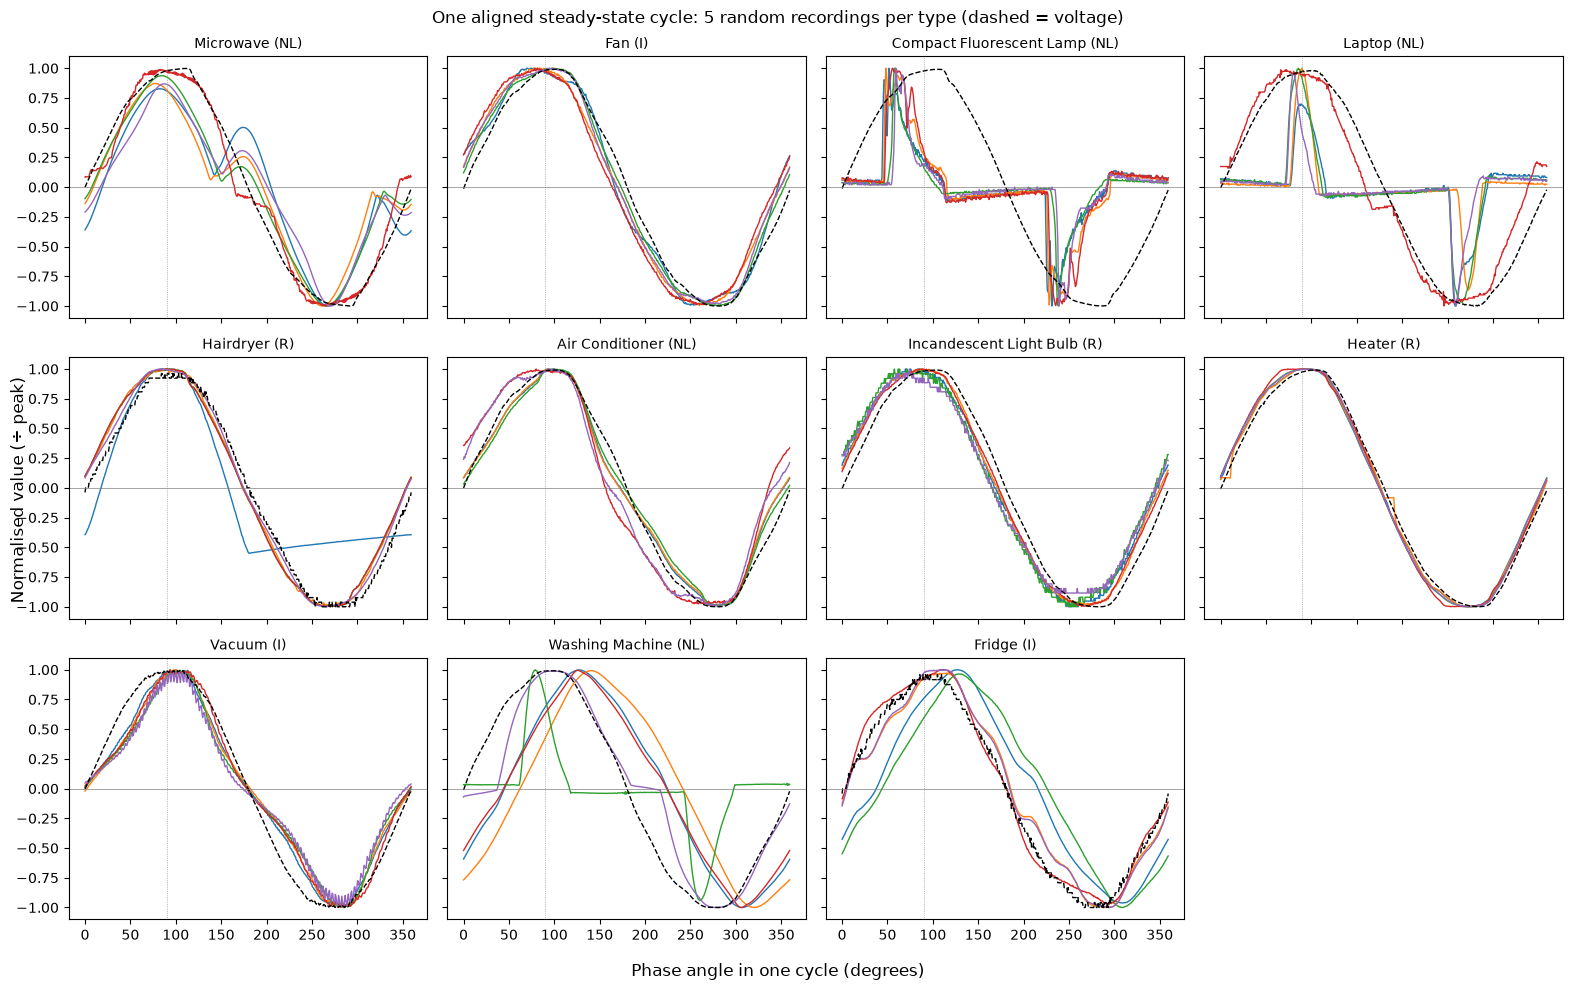

In [76]:
rng = np.random.default_rng(0)                             # same random picks every run
types = eda["type"].value_counts().index
load_of = meta.groupby("type")["load"].first()

fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, sharey=True)
for ax, t in zip(axes.flat, types):
    ids = eda.loc[eda["type"] == t, "id"].to_numpy()
    for rid in rng.choice(ids, size=min(5, len(ids)), replace=False):
        i, v = last_cycle(load_wave(rid))
        ax.plot(deg, i / np.abs(i).max(), linewidth=1)
    ax.plot(deg, v / np.abs(v).max(), "k--", linewidth=1)     # voltage reference
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(90, color="grey", linewidth=0.5, linestyle=":")
    ax.set_title(f"{t} ({load_of[t]})", fontsize=10)
axes.flat[-1].axis("off")

fig.supxlabel("Phase angle in one cycle (degrees)")
fig.supylabel("Normalised value (÷ peak)")
fig.suptitle("One aligned steady-state cycle: 5 random recordings per type (dashed = voltage)")
plt.tight_layout()
plt.show()

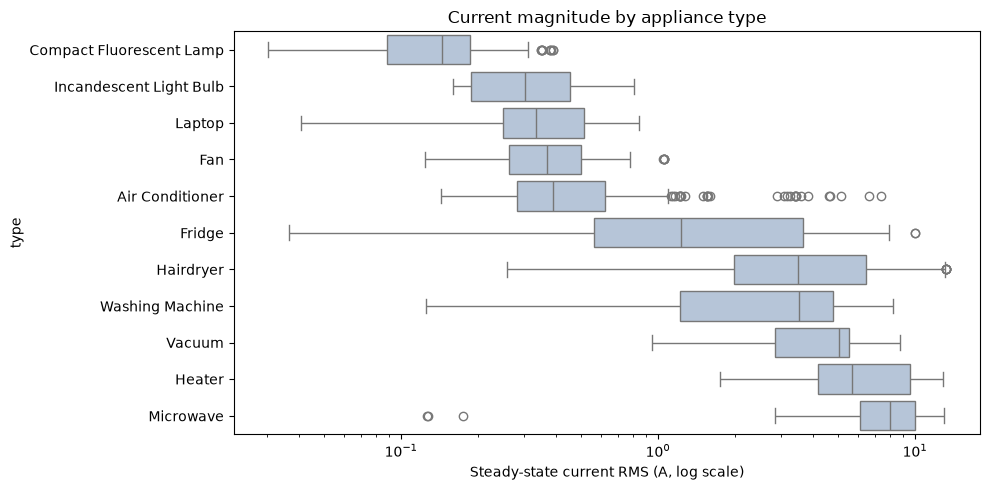

In [77]:
order = base.groupby("type")["i_rms_end"].median().sort_values().index
plt.figure(figsize=(10, 5))
sns.boxplot(data=base, y="type", x="i_rms_end", order=order, color="lightsteelblue")
plt.xscale("log")
plt.xlabel("Steady-state current RMS (A, log scale)")
plt.title("Current magnitude by appliance type")
plt.tight_layout()
plt.show()

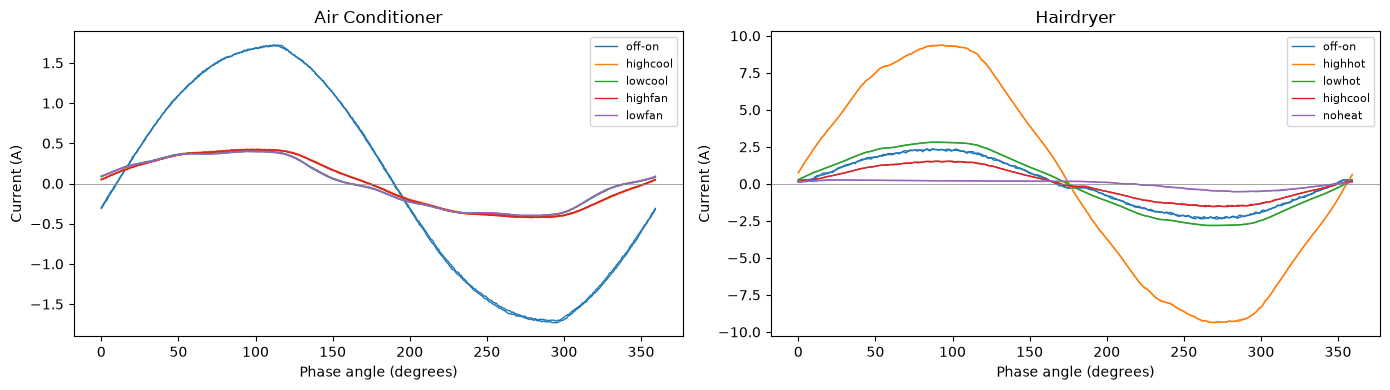

In [78]:
show = {"Air Conditioner": ["off-on", "highcool", "lowcool", "highfan", "lowfan"],
        "Hairdryer":       ["off-on", "highhot", "lowhot", "highcool", "noheat"]}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (t, statuses) in zip(axes, show.items()):
    for k, st in enumerate(statuses):
        ids = base.loc[(base["type"] == t) & (base["status"] == st), "id"].head(2)
        for j, rid in enumerate(ids):
            i, _ = last_cycle(load_wave(rid))
            ax.plot(deg, i, color=f"C{k}", linewidth=1, label=st if j == 0 else None)
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.set_title(t); ax.set_xlabel("Phase angle (degrees)"); ax.set_ylabel("Current (A)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [79]:
def phase_shift_deg(rec_id):
    """Phase of current vs voltage at 60 Hz (+ = current leads, - = current lags)."""
    i, v = last_cycle(load_wave(rec_id))
    I1, V1 = np.fft.rfft(i)[1], np.fft.rfft(v)[1]       # bin 1 = the 60 Hz fundamental
    return np.degrees(np.angle(I1 * np.conj(V1)))

r = eda[eda["type"].isin(["Heater", "Incandescent Light Bulb"])].copy()
r["shift_deg"] = r["id"].apply(phase_shift_deg)
display(r.groupby(["type", "collection_time"])["shift_deg"].describe()[["count", "mean", "std"]].round(1))

count  mean  std
type                    collection_time                  
Heater                  December, 2014    45.0   2.7  4.9
                        July, 2013        23.0   2.4  5.4
Incandescent Light Bulb August, 2017       1.0   8.0  NaN
                        December, 2014    29.0  10.0  1.0
                        July, 2013       108.0  11.6  1.9


**Finding (shape):** One aligned steady-state cycle shows three families:
- **In-step sine:** Heater, Incandescent bulb, Hairdryer, and Fan (capacitor-run motor, so PF ≈ 1 despite its "I" label).
- **Lagging sine:** Fridge (lag ≈ 20–40°, PF ≈ 0.94–0.77), Washing Machine spin (lag ≈ 30–60°), Vacuum
  (with fast brush ripple, a distinctive signature).
- **Pulses near the voltage peak:** CFL (pulse at ~60°) and Laptop (at the peak); Microwave has unequal halves.
Washing Machine (rinse vs spin), Fridge (compressor state) and Laptop (with/without power-factor correction)
contain clearly different sub-shapes. The bulb's current shows quantisation steps (~0.3 A vs 0.03 A resolution).

**Finding (magnitude):** Steady current spans ~0.03 A (CFL) to ~13 A (Heater, Microwave). Low group (0.1–0.6 A):
CFL, bulb, laptop, fan, AC. High group (2–13 A): hairdryer, washing machine, vacuum, heater, microwave.
Fridge spans both. **Hardest cluster: bulb vs fan vs AC** (same magnitude, similar sine shape);
**hardest pair: Heater vs Hairdryer.**

**Finding (modes):** AC cool and fan modes are identical (~0.4 A peak): the compressor is not running,
and the AC median (~0.4 A) shows most AC recordings capture only the fan. Hairdryer current varies 30×
across modes (no-heat ~0.3 A to high-hot ~9.3 A peak).

**Finding (phase):** Resistive loads lead the voltage slightly: Heater +2.4° (2013) / +2.7° (2014),
Incandescent bulb +11.6° / +10.0°. The batch difference is small (< 2°), so phase features carry little
batch signature. The bulb's consistent ~10° lead (std 1–2°) is a possible separating feature.

**Action:**
- Extract both **shape** features (PF, phase shift, crest factor, THD, odd/even harmonic ratios, V-I loop area)
  and **magnitude** features (I RMS, real power), plus **inrush** features to separate bulb/fan/AC.
- Add an even-harmonic (half-cycle asymmetry) feature for Microwave and half-wave Hairdryer settings.
- No phase correction needed: the batch difference is < 2°.
- Expect the most confusion within {bulb, fan, AC} and {Heater, Hairdryer}.

## 11. V-I Trajectories: Each Appliance's Signature Shape

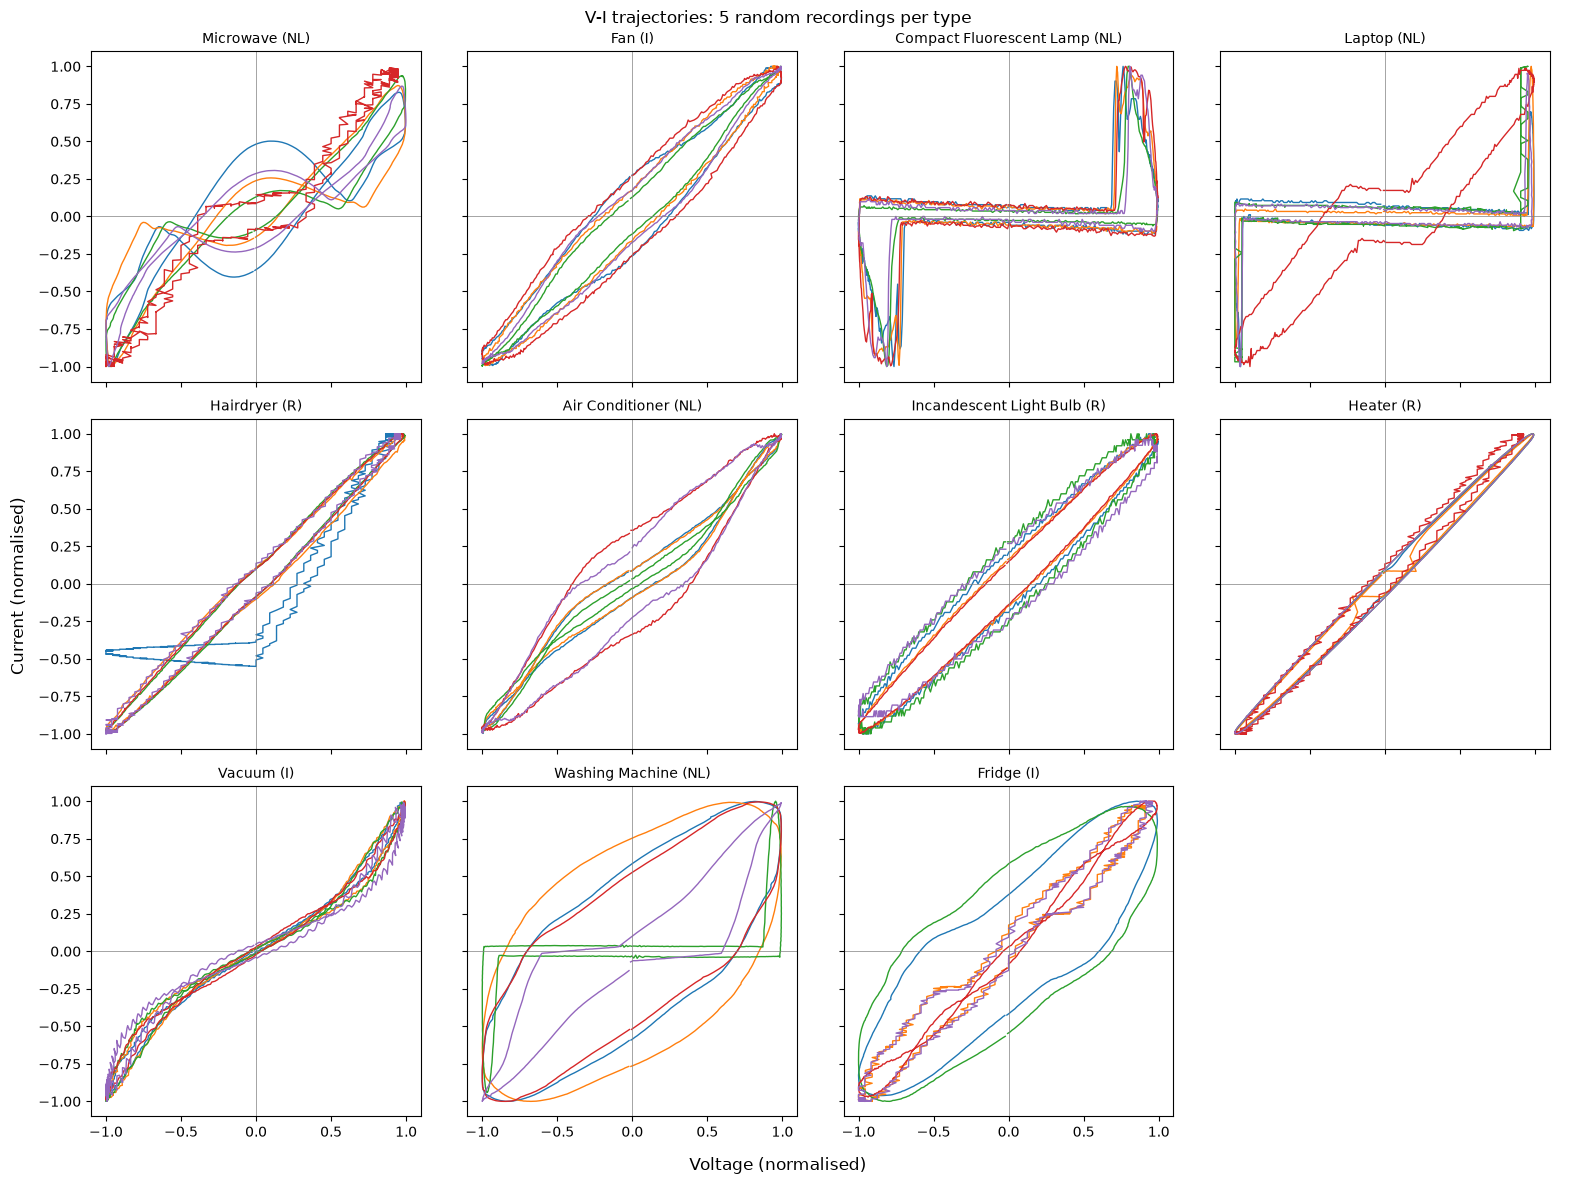

In [80]:
rng = np.random.default_rng(0)
types = eda["type"].value_counts().index

fig, axes = plt.subplots(3, 4, figsize=(16, 12), sharex=True, sharey=True)
for ax, t in zip(axes.flat, types):
    ids = eda.loc[eda["type"] == t, "id"].to_numpy()
    for rid in rng.choice(ids, size=min(5, len(ids)), replace=False):
        i, v = last_cycle(load_wave(rid))
        ax.plot(v / np.abs(v).max(), i / np.abs(i).max(), linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    ax.set_title(f"{t} ({load_of[t]})", fontsize=10)
    ax.set_aspect("equal")
axes.flat[-1].axis("off")

fig.supxlabel("Voltage (normalised)")
fig.supylabel("Current (normalised)")
fig.suptitle("V-I trajectories: 5 random recordings per type")
plt.tight_layout()
plt.show()

type
Microwave                   30
Washing Machine             30
Fan                         30
Air Conditioner             30
Incandescent Light Bulb     30
Laptop                      30
Heater                      30
Vacuum                      30
Hairdryer                   30
Compact Fluorescent Lamp    30
Fridge                      30
Name: count, dtype: int64


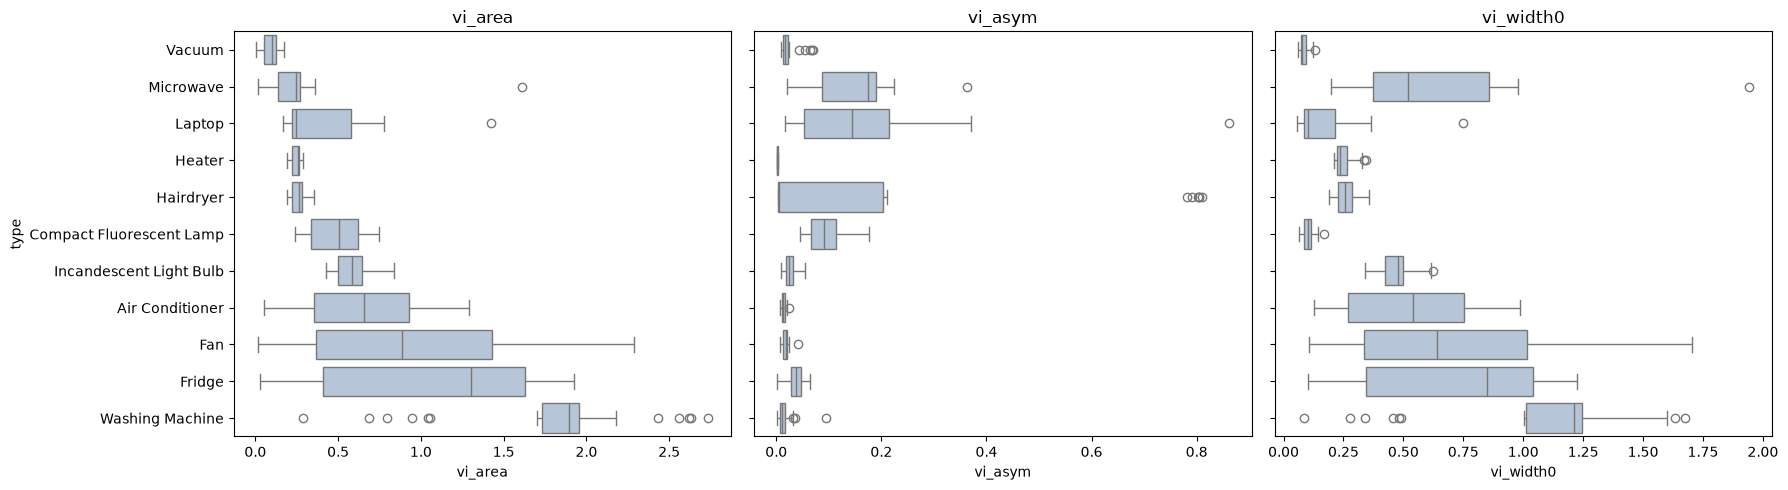

In [81]:
smp = eda.sample(frac=1, random_state=0).groupby("type").head(30)
print(smp["type"].value_counts())
def vi_features(rec_id):
    i, v = last_cycle(load_wave(rec_id))
    i_n, v_n = i / np.abs(i).max(), v / np.abs(v).max()

    area = 0.5 * abs(np.sum(v_n * np.roll(i_n, -1) - np.roll(v_n, -1) * i_n))   # shoelace formula
    half = SPC // 2
    asym = np.mean(np.abs(i_n[:half] + i_n[half:])) / np.mean(np.abs(i_n))

    near0 = np.abs(v_n) < 0.05                       # points where voltage is close to zero
    width0 = np.ptp(i_n[near0]) if near0.any() else np.nan

    return {"id": rec_id, "vi_area": area, "vi_asym": asym, "vi_width0": width0}

vi = pd.DataFrame([vi_features(r) for r in tqdm(smp["id"])])
vi = smp[["id", "type"]].merge(vi, on="id")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
order = vi.groupby("type")["vi_area"].median().sort_values().index
for ax, col in zip(axes, ["vi_area", "vi_asym", "vi_width0"]):
    sns.boxplot(data=vi, y="type", x=col, order=order, ax=ax, color="lightsteelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

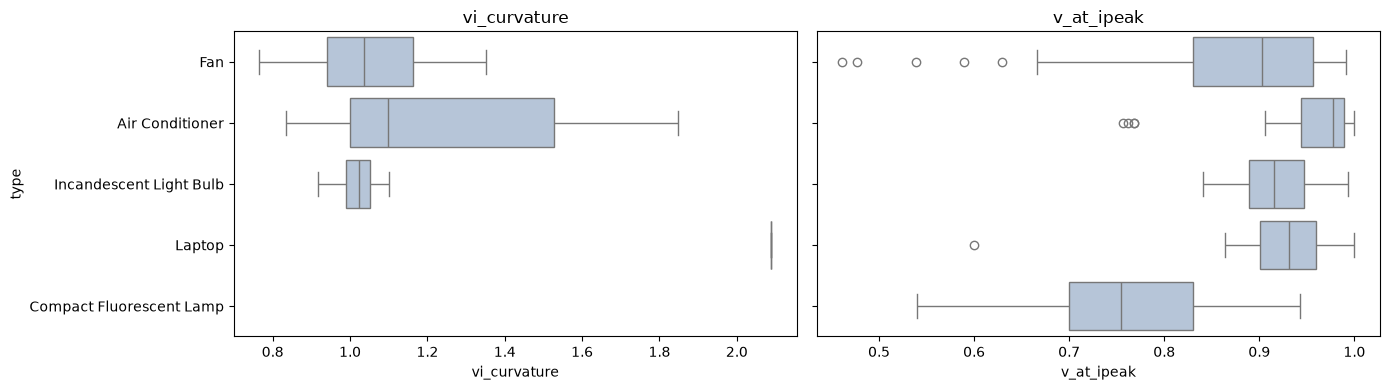

In [82]:
def vi_shape_extra(rec_id):
    i, v = last_cycle(load_wave(rec_id))
    i_n, v_n = i / np.abs(i).max(), v / np.abs(v).max()

    mid, end = np.abs(v_n) < 0.3, np.abs(v_n) > 0.7
    s_mid = np.polyfit(v_n[mid], i_n[mid], 1)[0]          # slope near zero voltage
    s_end = np.polyfit(v_n[end], i_n[end], 1)[0]          # slope near the voltage peaks
    curvature = s_end / s_mid if abs(s_mid) > 0.3 else np.nan
    v_at_ipeak = abs(v_n[np.argmax(np.abs(i_n))])         # where on the voltage axis the current peaks
    return {"id": rec_id, "vi_curvature": curvature, "v_at_ipeak": v_at_ipeak}

extra = pd.DataFrame([vi_shape_extra(r) for r in smp["id"]])
vi = vi.drop(columns=["vi_curvature", "v_at_ipeak"], errors="ignore").merge(extra, on="id")

cluster = vi[vi["type"].isin(["Incandescent Light Bulb", "Fan", "Air Conditioner", "CFL", "Compact Fluorescent Lamp", "Laptop"])]
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, col in zip(axes, ["vi_curvature", "v_at_ipeak"]):
    sns.boxplot(data=cluster, y="type", x=col, ax=ax, color="lightsteelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

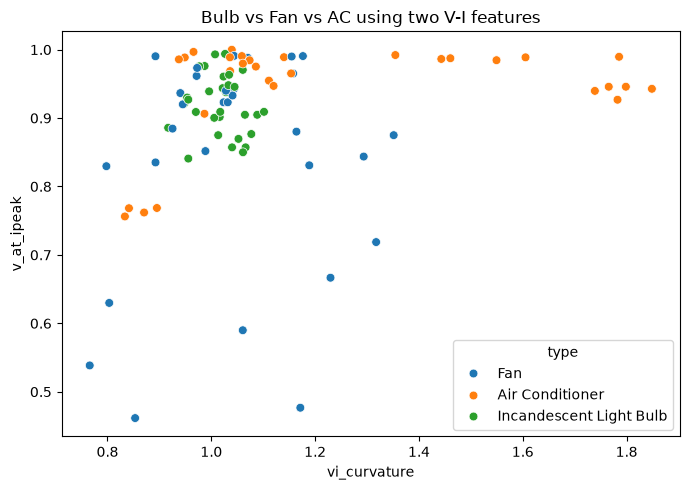

In [83]:
c3 = vi[vi["type"].isin(["Incandescent Light Bulb", "Fan", "Air Conditioner"])]
plt.figure(figsize=(7, 5))
sns.scatterplot(data=c3, x="vi_curvature", y="v_at_ipeak", hue="type", s=40)
plt.title("Bulb vs Fan vs AC using two V-I features")
plt.tight_layout()
plt.show()

A V-I trajectory plots current (y) against voltage (x) over one steady-state cycle, both normalised by their peaks.
Each appliance draws a closed loop whose shape is a strong signature.

**Finding (shapes, 5 recordings per type):**

| Shape | Types | Meaning |
|---|---|---|
| Thin straight line | Heater, Hairdryer | Resistive: current ∝ voltage |
| Thin ellipse | Incandescent bulb, Fan | Small phase shift |
| Fat ellipse | Fridge, Washing Machine (spin) | Large phase shift (motor) |
| S-curve | Vacuum, Air Conditioner | Current not proportional to voltage (motor non-linearity) |
| Z-shape with vertical spikes | CFL, Laptop | Current flows only near the voltage peak (rectifier) |
| Irregular, self-crossing loop | Microwave | Positive and negative halves differ |

- Washing Machine contains two sub-shapes (spin ellipse vs rinse Z-shape), and Laptop two (Z-shape vs a
  power-factor-corrected parallelogram).
- One Hairdryer setting removes the negative half-cycle (half-wave diode setting).
- Low-current recordings (some bulbs, fridges) show staircase steps from the sensor's ~0.03 A resolution.

**Finding (features, 30 recordings per type):**
- **Loop area** gives the phase shift for sine-like loads (φ = arcsin(A/π)): Heater ≈ 5°, bulb ≈ 11°, Fan ≈ 17°,
  Fridge ≈ 24°, Washing Machine ≈ 37°. The bulb value matches the independent phase test (+10–11.6°).
  Vacuum has the smallest area (~0.1) despite its distinctive S-curve.
- **Half-cycle asymmetry** is high for Microwave (~0.17), Laptop (~0.15) and the half-wave Hairdryer setting (~0.8),
  and ~0 for symmetric loads (Heater, Fan, AC, Vacuum, Washing Machine).
- **Width at zero voltage** is highest for Washing Machine (~1.2) and lowest for Vacuum, CFL and Laptop (~0.1).
- **Voltage at current peak** cleanly separates CFL (median 0.755) from Laptop (0.93); AC peaks closest to the
  voltage peak (0.975).
- **V-I curvature** (end slope ÷ middle slope) is ~1.0 for bulb and Fan and 1.0–1.5 for AC (S-curve), so AC is
  partly separable. It is not meaningful for Z-shaped loads (CFL, Laptop), where the middle slope is ~0.

**Finding (hard cases):**

| Pair | Separated by | Status |
|---|---|---|
| CFL vs Laptop | Voltage at current peak | Solved |
| AC vs Fan / bulb | Curvature + voltage at current peak together | Partly |
| Fan vs bulb | No V-I feature | Unsolved: needs inrush and harmonic (THD) features |
| Heater vs Hairdryer | No V-I feature (both straight lines) | Unsolved: needs magnitude, inrush and mode-related features |

**Action:**
- Use as features: loop area, half-cycle asymmetry, width at zero voltage, voltage at current peak, and V-I curvature
  (computed only when the middle slope > 0.3; otherwise missing).
- Impute missing curvature **inside the training pipeline** (median learned from training folds only).
- Add inrush and THD features to separate Fan vs bulb and Heater vs Hairdryer.
- V-I images are a candidate input for a later CNN model (De Baets et al., 2018).

## 12. Aggregated Data: Several Appliances Running Together

In [84]:
with open(DATA / "metadata_aggregated.json") as f:
    meta_agg = json.load(f)

rec_rows, ev_rows = [], []
for k, r in meta_agg.items():
    apps = r["appliances"]
    rec_rows.append({
        "id":              int(k),
        "n_apps":          len(apps),
        "length_s":        float(r["instances"]["length"].rstrip("s")),
        "status":          r["instances"]["status"],
        "location":        r["location"],
        "collection_time": r["header"]["collection_time"],
        "types":           " + ".join(sorted(a["type"] for a in apps)),
    })
    for a in apps:
        t = NAME_MAP.get(a["type"], a["type"])
        for s in re.findall(r"\d+", a["on"]):
            ev_rows.append({"id": int(k), "type": t, "event": "ON",  "sample": int(s)})
        for s in re.findall(r"\d+", a["off"]):
            ev_rows.append({"id": int(k), "type": t, "event": "OFF", "sample": int(s)})

agg = pd.DataFrame(rec_rows).sort_values("id").reset_index(drop=True)
ev  = pd.DataFrame(ev_rows).sort_values(["id", "sample"]).reset_index(drop=True)
ev["time_s"] = ev["sample"] / FS
print("Recordings:", agg.shape, "| events:", ev.shape)

Recordings: (575, 7) | events: (2714, 5)


In [85]:
file_ids = {int(p.stem) for p in AGG.glob("*.csv") if p.stem.isdigit()}
print("CSV files:", len(file_ids), "| metadata:", len(agg))
print("Files without metadata:", sorted(file_ids - set(agg["id"])))
print("Metadata without file:", sorted(set(agg["id"]) - file_ids))

print("\nAppliances per recording:\n", agg["n_apps"].value_counts().sort_index())
print("\nLength (s):\n", agg["length_s"].describe().round(2))
print("\nLocation / batch:\n", agg[["location", "collection_time"]].value_counts())

print("\nRecordings per appliance type:\n",
      ev.groupby("type")["id"].nunique().sort_values(ascending=False))
print("\nTypes not found in submetered:", sorted(set(ev["type"]) - set(meta["type"])))

CSV files: 576 | metadata: 575
Files without metadata: [0]
Metadata without file: []

Appliances per recording:
 n_apps
2    443
3    111
4     21
Name: count, dtype: int64

Length (s):
 count    575.00
mean      13.95
std        4.63
min       10.00
25%       10.00
50%       10.00
75%       20.00
max       30.00
Name: length_s, dtype: float64

Location / batch:
 location  collection_time
CMU lab   August, 2017       575
Name: count, dtype: int64

Recordings per appliance type:
 type
Air Conditioner             159
Incandescent Light Bulb     112
Water kettle                110
Soldering Iron              109
Coffee maker                106
Compact Fluorescent Lamp    103
Fan                         101
Vacuum                       98
Hair Iron                    97
Laptop                       90
Fridge defroster             88
Fridge                       79
Blender                      51
Name: id, dtype: int64

Types not found in submetered: ['Fridge defroster']


Events per recording:
 count    575.0
mean       4.7
std        1.1
min        4.0
25%        4.0
50%        4.0
75%        5.0
max        9.0
dtype: float64

Gap between consecutive events (s):
 count    2139.00
mean        2.49
std         1.36
min         0.03
25%         1.60
50%         2.12
75%         3.08
max         8.36
Name: gap_prev_s, dtype: float64
Events < 0.5 s after the previous one: 61

First event time (s):
 count    575.00
mean       1.56
std        0.52
min        0.28
25%        1.26
50%        1.46
75%        1.77
max        4.32
Name: time_s, dtype: float64

Time from last event to file end (s):
 count    575.00
mean       3.14
std        3.90
min       -9.95
25%        1.63
50%        2.70
75%        4.15
max       17.03
dtype: float64


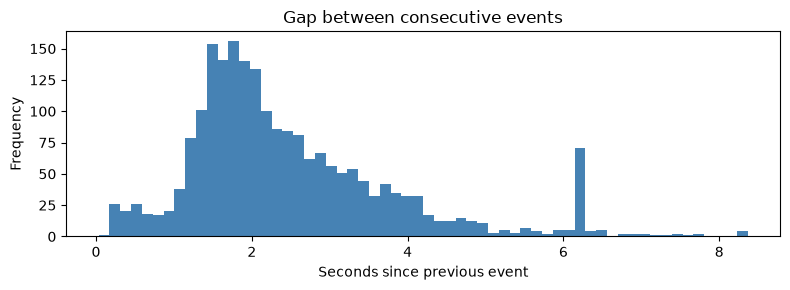

In [86]:
ev["gap_prev_s"] = ev.groupby("id")["time_s"].diff()          # time since previous event
ev["gap_next_s"] = -ev.groupby("id")["time_s"].diff(-1)       # time until next event

first = ev.groupby("id")["time_s"].min()
tail  = agg.set_index("id")["length_s"] - ev.groupby("id")["time_s"].max()

print("Events per recording:\n", ev.groupby("id").size().describe().round(1))
print("\nGap between consecutive events (s):\n", ev["gap_prev_s"].describe().round(2))
print("Events < 0.5 s after the previous one:", (ev["gap_prev_s"] < 0.5).sum())
print("\nFirst event time (s):\n", first.describe().round(2))
print("\nTime from last event to file end (s):\n", tail.describe().round(2))

plt.figure(figsize=(8, 3))
ev["gap_prev_s"].dropna().plot(kind="hist", bins=60, color="steelblue")
plt.xlabel("Seconds since previous event"); plt.title("Gap between consecutive events")
plt.tight_layout(); plt.show()

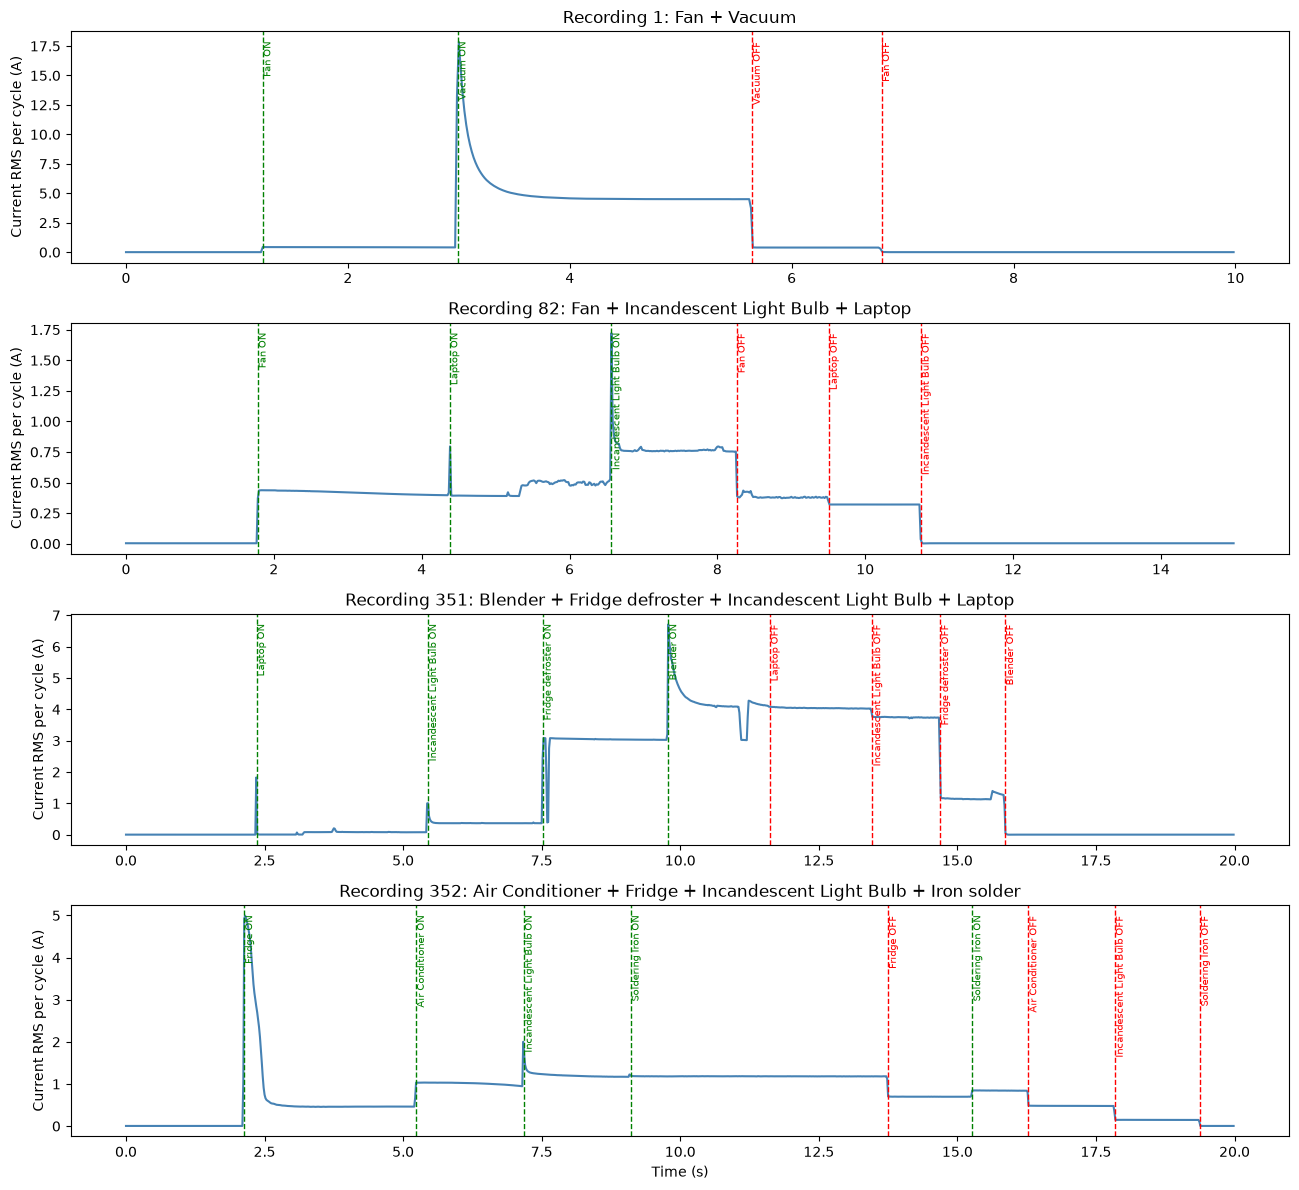

In [87]:
def cycle_rms(i):
    n = len(i) // SPC
    return np.sqrt((i[:n * SPC].reshape(n, SPC) ** 2).mean(axis=1))

examples = [agg.loc[agg["n_apps"] == n, "id"].iloc[0] for n in (2, 3, 4)]
examples.append(ev.groupby("id").size().idxmax())              # the busiest recording

fig, axes = plt.subplots(len(examples), 1, figsize=(13, 3 * len(examples)))
for ax, rid in zip(axes, examples):
    i = pd.read_csv(AGG / f"{rid}.csv", header=None, usecols=[0])[0].to_numpy()
    rms = cycle_rms(i)
    ax.plot(np.arange(len(rms)) / 60, rms, color="steelblue")
    for _, e in ev[ev["id"] == rid].iterrows():
        c = "green" if e["event"] == "ON" else "red"
        ax.axvline(e["time_s"], color=c, linestyle="--", linewidth=1)
        ax.text(e["time_s"], rms.max(), f" {e['type']} {e['event']}", color=c, fontsize=7,
                rotation=90, va="top")
    ax.set_title(f"Recording {rid}: {agg.loc[agg['id'] == rid, 'types'].item()}")
    ax.set_ylabel("Current RMS per cycle (A)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

In [88]:
def delta_rms(rec_id, sample, gap=0.2, settle=0.5, n=10):
    """RMS of (mean cycle after event) - (mean cycle before event) = the new appliance's current."""
    w = pd.read_csv(AGG / f"{rec_id}.csv", header=None, names=["current", "voltage"])
    i, v = w["current"].to_numpy(), w["voltage"].to_numpy()
    r = rising_crossings(v)
    pre  = r[r + SPC <= sample - int(gap * FS)][-n:]            # n cycles ending 0.2 s before
    post = r[r >= sample + int(settle * FS)][:n]                # n cycles starting 0.5 s after
    post = post[post + SPC <= len(i)]
    if len(pre) < n or len(post) < n:
        return np.nan
    before = np.mean([i[k:k + SPC] for k in pre], axis=0)
    after  = np.mean([i[k:k + SPC] for k in post], axis=0)
    return np.sqrt(np.mean((after - before) ** 2))

iso = ev[(ev["event"] == "ON")
         & (ev["gap_prev_s"].fillna(99) >= 1)
         & (ev["gap_next_s"].fillna(99) >= 1)].copy()          # no other event within 1 s
iso = iso.groupby("type").head(15)                              # up to 15 per type, for speed
iso["delta_rms"] = [delta_rms(r, s) for r, s in zip(iso["id"], iso["sample"])]

lab_med = chk[chk["location"] == "CMU lab"].groupby("type")["i_rms_end"].median()
comp = (iso.groupby("type")["delta_rms"].median().rename("agg_step_A").to_frame()
           .join(lab_med.rename("submetered_lab_A")))
comp["ratio"] = (comp["agg_step_A"] / comp["submetered_lab_A"]).round(2)
display(comp.round(3))

,agg_step_A,submetered_lab_A,ratio
type,,,
Air Conditioner,0.530,0.457,1.16
Blender,1.219,0.815,1.49
Coffee maker,3.188,3.200,1.00
Compact Fluorescent Lamp,0.064,0.065,0.99
Fan,0.430,0.436,0.99
Fridge,0.995,3.232,0.31
Fridge defroster,2.721,NaN,NaN
Hair Iron,0.629,0.570,1.11
Incandescent Light Bulb,0.324,0.325,1.00


In [89]:
# a) Events labelled after the file ends
late = ev.merge(agg[["id", "length_s"]], on="id").query("time_s > length_s")
print("Events after file end:", len(late), "in", late["id"].nunique(), "recordings")
display(late[["id", "type", "event", "time_s", "length_s"]].head(10))

# b) What causes the ~6.2 s spike in gaps?
spike = ev[ev["gap_prev_s"].between(6.1, 6.3)]
display(spike["type"].value_counts().head(), spike["event"].value_counts())

Events after file end: 131 in 44 recordings


,id,type,event,time_s,length_s
1491,327,Air Conditioner,OFF,10.945400,10.0
1492,327,Compact Fluorescent Lamp,OFF,12.538500,10.0
1493,327,Fridge defroster,OFF,14.164600,10.0
1504,329,Soldering Iron,ON,10.898867,10.0
1505,329,Hair Iron,OFF,11.904400,10.0
1506,329,Compact Fluorescent Lamp,OFF,13.907900,10.0
1507,329,Soldering Iron,OFF,15.674000,10.0
1532,333,Fridge,ON,12.063900,10.0
1533,333,Incandescent Light Bulb,OFF,13.841100,10.0
1534,333,Fridge,OFF,14.949933,10.0


type
Soldering Iron             71
Incandescent Light Bulb     1
Fridge                      1
Hair Iron                   1
Name: count, dtype: int64

event
ON     72
OFF     2
Name: count, dtype: int64

**Aggregated Data: Explored, Not Used in This Model**

**Scope:** Stage 1 identifies single appliances from submetered recordings, so the aggregated data
(several appliances running at once) is **not used** for training or testing.

**Why it is excluded:**
- All 575 recordings come from **one location (CMU lab, Aug 2017)**, using the **same physical appliances** as the
  submetered lab recordings, so it cannot test performance on unseen homes and would leak known appliances.
- It contains data-quality issues: `0.csv` has no metadata, and **131 events in 44 recordings are labelled after
  the file ends** (recordings cut at 10 s while the experiment continued).

**What it showed:**
- 2–4 appliances per recording (443 / 111 / 21), 2,714 labelled ON/OFF events, median gap 2.12 s.
- **Currents add sample by sample**: subtracting the cycles before a switch-on from the cycles after recovers the
  appliance's current (ratio 0.99–1.00 vs the same appliance measured alone for 5 types).
- Fridge (0.31) and Vacuum (0.81) deviate because the 0.7 s submetered lab files were measured during the
  switch-on surge, independently confirming the short-recording problem from Section 7.

**Future work:** event detection (Stage 2) and waveform subtraction + identification (Stage 3).

## 13. Key Findings and Cleaning Plan


### 13.1 Key findings

| # | Finding | Section | Consequence |
|---|---|---|---|
| 1 | Classes are imbalanced 123 : 1; 5 types (52 recordings) come only from the CMU lab | 3–4 | Main experiment uses 11 household types; report macro-F1 |
| 2 | 56 locations, very uneven; each appliance is recorded 4–11 times in the same home | 4 | Split by home (grouped CV); otherwise scores are over-optimistic |
| 3 | Batches are confounded with type; Jul 2013 voltage was rescaled to exactly 120 V | 5, 9 | No batch or V RMS features; prefer shape features; evaluate per batch |
| 4 | 26% of recordings are in operating modes; AC "cool" = fan only; Hairdryer current varies 30× | 6, 10 | Keep modes; analyse errors per mode |
| 5 | 0.7 s lab recordings capture the switch-on surge, not steady state (confirmed by aggregated subtraction: Fridge 0.31, Vacuum 0.81) | 7, 12 | Flag them; take the steady window after the surge settles |
| 6 | Nameplate fields are 56–99% missing and unreliable (mixed units, spreadsheet date error, copy-paste carry-over) | 7–8 | Never used as features |
| 7 | All 1,876 files match their metadata exactly, but 5 laptop files appear under two homes | 9 | Drop the duplicate copies |
| 8 | 43 recordings draw < 0.05 A, near the 0.03 A sensor resolution; 78 recordings caught a low-power state | 9 | Drop < 0.03 A; flag low-power states |
| 9 | Noise near 0 V adds false zero crossings (452 files); 35 files have voltage spikes > 200 V (34 from 2013) | 9 | Robust cycle alignment; check spikes inside the feature window |
| 10 | Three waveform families and six V-I shapes separate most types; hardest cases are {bulb, Fan, AC} and {Heater, Hairdryer} | 10–11 | Add inrush and THD features |

### 13.2 Cleaning plan (before the train/test split)

These steps are **row filters or per-recording transforms**: they do not learn any number from the data,
so they are safe to apply before splitting.

| Step | Action | Recordings | Reason |
|---|---|---|---|
| 1 | Drop the 5 lab-only types | −52 | One location: cannot be tested on unseen homes |
| 2 | Drop duplicate copies, ids 367–371 | −5 | Byte-identical to ids 222–226 in another home (leakage) |
| 3 | Drop steady current < 0.03 A | −9 (Laptop; id 454 kept: steady ON before the end) | Below sensor resolution: shape features are noise |
| 4 | Rescale each recording's voltage to 120 V RMS | all | Removes the batch voltage difference (2013 fixed at 120 V) |
| 5 | Align cycles with robust zero crossings (min gap 0.8 cycle) | all | Noise near 0 V creates false crossings |
| 6 | Take the window from the longest stable segment after switch-on | all | Avoids the surge in short recordings |
| 7 | Flag (keep): short-window, low-power-state, spike-in-window, 0.03–0.05 A | 176 flagged | Used for sensitivity checks |
| 8 | Drop `0.csv` and the aggregated set from this model | n/a | Out of scope (single lab, same appliances) |

**Expected main dataset:** 1,876 − 52 − 5 − 9 = **1,810 recordings, 11 types, 56 locations**
(confirm with the cleaning log below).

### 13.3 Preprocessing inside the pipeline (fitted on training folds only)

| Step | Tool | Why inside the pipeline |
|---|---|---|
| Impute missing values (e.g. V-I curvature for CFL/Laptop, inrush when no switch-on) | `SimpleImputer(strategy="median")` | The median must come from training data only |
| Log-transform heavy-tailed magnitudes (I RMS, power) | `np.log1p` | Spreads 0.03–13 A evenly (fixed formula, no learning) |
| Scale features | `RobustScaler` | Extreme values are real physics (heaters), not errors |
| Optional dimensionality reduction | `PCA(0.95)` | Learns directions from training data |
| Handle imbalance | `class_weight="balanced"` | No resampling before the split |

### 13.4 Feature plan

**Use (extracted from the waveforms):**
- **Magnitude:** I RMS, I peak, real / apparent / reactive power (at 120 V)
- **Shape:** power factor, phase shift, crest factor, THD, harmonic ratios (H3, H5, H7 ÷ H1), even harmonics / half-cycle asymmetry
- **V-I:** loop area, width at zero voltage, voltage at current peak, curvature
- **Transient:** inrush ratio (surge peak ÷ steady peak), settling time

**Never use (leakage or not available for a new appliance):**
`load`, `status` / mode, `collection_time` / batch, `location` (used only as the split group), `length_s`,
nameplate fields (brand, wattage, current, voltage, model, year), `notes`, `id`, V RMS (identifies the batch).

### 13.5 Evaluation plan

- `StratifiedGroupKFold(n_splits=5)` with `groups = location`; check that every class appears in every test fold.
- Report **macro-F1 (mean ± std across folds)** against a majority-class baseline (13.1% accuracy).
- Error analysis: confusion matrix, and errors per **mode**, per **batch** and per **home**.
- Sensitivity checks: with vs without flagged recordings (short-window, low-power state).
- For comparison only: a record-level split, to show how much leakage inflates the score.

### 13.6 Open questions
- How many voltage spikes fall inside the feature window (step 7)?
- How many AC recordings actually contain compressor operation?
- Do inrush and THD separate Fan from bulb, and Heater from Hairdryer?

## 14. Data Cleaning: Applying the Plan

This step applies the cleaning plan from Section 13 and records a **cleaning log** (recordings, types and
locations remaining after each step).

**Two kinds of action:**
- **Filters** remove recordings that cannot be used: they are out of scope, duplicated, or below the sensor's resolution.
- **Flags** mark recordings that are usable but questionable. They are **kept**, so models can later be trained
  with and without them (sensitivity check).

**Why this is safe before the train/test split:** every step is a fixed rule applied to one recording at a time.
None of them learns a number from the data (no means, medians or scaling), so no information leaks from
test data into training. Steps that learn numbers (imputation, scaling) happen later, inside the pipeline.

| Step | Type | Rule | Reason |
|---|---|---|---|
| 1 | Filter | Drop the 5 lab-only types | One location only: cannot be tested on unseen homes |
| 2 | Filter | Drop ids 367–371 | Byte-identical copies of ids 222–226 from another home (leakage) |
| 3 | Filter | Drop steady current < 0.03 A (id 454 kept: steady ON earlier) | Below sensor resolution: waveform shape is noise |
| 4 | Flag | `flag_short`: switch-on too close to the end of the recording | Steady-state window may contain the switch-on surge |
| 5 | Flag | `flag_low_state`: current < 0.2 × type median | Appliance caught in a low-power state (compressor off, idle, standby) |
| 6 | Flag | `flag_spike`: voltage peak > 200 V | Voltage spike may distort features |
| 7 | Flag | `flag_low_amp`: current < 0.05 A | Close to sensor resolution: features less reliable |

In [90]:
lab_only = ["Blender", "Coffee maker", "Water kettle", "Hair Iron", "Soldering Iron"]
log = []

def step(df, name):
    log.append({"step": name, "recordings": len(df),
                "types": df["type"].nunique(), "locations": df["location"].nunique()})
    return df

d = step(chk.copy(),                                   "Start: all submetered recordings")
d = step(d[~d["type"].isin(lab_only)],                 "1. Drop 5 lab-only types")
d = step(d[~d["id"].isin(range(367, 372))],            "2. Drop duplicate copies (367-371)")
d = step(d[(d["i_rms_end"] >= 0.03) | (d["id"] == 454)],
         "3. Drop current < 0.03 A (keep 454: steady ON earlier)")

# Step 7: flags (kept, used for sensitivity checks)
d["flag_short"]     = d["id"].isin(set(short.loc[short["too_close"], "id"]))
d["flag_low_state"] = d["ratio"] < 0.2
d["flag_spike"]     = d["v_peak"] > 200
d["flag_low_amp"]   = d["i_rms_end"] < 0.05
flag_cols = ["flag_short", "flag_low_state", "flag_spike", "flag_low_amp"]

display(pd.DataFrame(log))
print("\nFlagged recordings:\n", d[flag_cols].sum())
print("Recordings with at least one flag:", d[flag_cols].any(axis=1).sum())

d.to_csv(DATA / "clean_index.csv", index=False)       # the input list for feature extraction

,step,recordings,types,locations
0,Start: all submetered recordings,1876,16,56
1,1. Drop 5 lab-only types,1824,11,56
2,2. Drop duplicate copies (367-371),1819,11,56
3,3. Drop current < 0.03 A (keep 454: steady ON earlier),1810,11,56



Flagged recordings:
 flag_short        70
flag_low_state    61
flag_spike        34
flag_low_amp      24
dtype: int64
Recordings with at least one flag: 176


**Result:**

| Step | Recordings | Types | Locations |
|---|---|---|---|
| Start: all submetered recordings | 1,876 | 16 | 56 |
| 1. Drop 5 lab-only types | 1,824 | 11 | 56 |
| 2. Drop duplicate copies (367–371) | 1,819 | 11 | 56 |
| 3. Drop current < 0.03 A (keep 454: steady ON earlier) | 1,810 | 11 | 56 |

**Flagged (kept):** short window 70, low-power state 61, voltage spike 34, low amplitude 24
(176 recordings have at least one flag; a recording can have more than one).

**Finding:** The final dataset has **1,810 recordings across 11 appliance types and 56 locations**.
Filtering removed 66 recordings (3.5%): 52 lab-only recordings, 5 duplicate copies and 9 laptop recordings
below the sensor's resolution. No location was lost, so the unseen-home split still has all 56 groups
(including the CMU lab, which keeps 80 household-type recordings).
The flagged recordings are kept for sensitivity checks. The cleaned list is saved in `clean_index.csv`,
the input for feature extraction (`02_feature_extraction.ipynb`).